# Appendix tables and numbers of the text (exact duplicates of the target row, r = 0)

Reads `data/measurements.parquet` and `config.yaml`. Writes `paper/gen/app_*.tex` (tables), `paper/gen/fig_*.pdf`
(figures), `paper/gen/csv/*.csv` (the same tables) and `paper/gen/zahlen.tex` (numbers for the text). Run all cells
from the top; nothing is entered by hand. Every cell shows its result.

Attack: b random context rows overwritten by an exact copy of the target row with the WRONG label; control arm:
the same rows, the same copy, the TRUE label. Budgets b = 1, ..., 5. Only measured quantities, counted and
averaged; per dataset first, then mean (± SD) over the datasets; b* as a median; descriptive throughout, the 25 tests of the manuscript are in paper/tests_v5.py.
Datasets: those complete for all three models; the notebook says which.

In [1]:
from pathlib import Path
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy import stats

# Paths: the notebook may run in paper/ or in the project root.
ROOT = Path.cwd().resolve()
if ROOT.name == "paper":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "measurements.parquet"           # keys, outcome, neighbourhood, vote (core/table.py, SCHEMA.md)
GEN = ROOT / "paper" / "gen"
CSV = GEN / "csv"
CSV.mkdir(parents=True, exist_ok=True)
CFG = yaml.safe_load((ROOT / "config.yaml").read_text())

# The three models (internal name, label in the tables), short dataset names for the tables,
# and the design from config.yaml (budgets, folds).
MODELS = [("tabicl-n8", "TabICL"), ("tabpfn35-n8", "TabPFN"), ("catboost", "CatBoost")]
TFMS = MODELS[:2]
LAB = dict(MODELS)
SHORT = {"banknote-authentication": "banknote", "climate-model-simulation-crashes": "climate-model",
         "Pulsar-Dataset-HTRU2": "Pulsar-Dataset", "electrical_grid_stability": "electrical_grid",
         "hazelnut-spread-contaminant": "hazelnut-spread", "polish_companies_bankruptcy": "polish_companies"}
DIDS = {d["name"]: d["did"] for d in CFG["datasets"]}
BUDGETS = [int(b) for b in CFG["design"]["budgets"]]
FOLDS = int(CFG["design"]["folds"])
KT = ["dataset", "fold", "target"]
# A group (e.g. flipped target rows of one dataset) counts only with at least this many rows.
MIN_ZIEL = 1
# The models with the vote (a_T, a_F, a_P) and the numbers of copies they have it at: TabPFN from its decoder at
# every budget. TabICL has no vote (its decoder is an MLP), it is read by its relative closeness m (paper/zahlen_lage.py).
VOTE_B = {"tabpfn35-n8": BUDGETS}
VOTE_TAG = {"tabpfn35-n8": "pfn"}
display(pd.DataFrame({"setting": ["budgets", "folds", "models", "config datasets"],
                      "value": [BUDGETS, FOLDS, [l for _, l in MODELS], len(DIDS)]}))

,setting,value
0,budgets,"[1, 2, 3, 4, 5]"
1,folds,5
2,models,"[TabICL, TabPFN, CatBoost]"
3,config datasets,30


## Figure style

Colours and fonts of the figures, the same in every figure. `sichern()` writes a figure
to `gen/` and shows it here.

In [2]:
%matplotlib inline
TINTE, TINTE2, LEISE, RASTER, ACHSE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
HINTERGRUND = "#f5f4f1"
# model colours (Okabe-Ito green and purple, grey): blue and orange stay reserved for the true and the
# wrong label in the figures of D to F
FARBE = {"tabicl-n8": "#1b8a6b", "tabpfn35-n8": "#9b4f96", "catboost": "#52514e"}
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Cantarell", "Segoe UI", "Roboto", "Helvetica", "Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 9.5, "text.color": TINTE, "axes.labelcolor": TINTE2, "axes.labelsize": 9.5,
    "figure.facecolor": "white", "axes.facecolor": HINTERGRUND, "savefig.facecolor": "white",
    "axes.edgecolor": ACHSE, "axes.linewidth": 0.8, "axes.titlesize": 9.5, "axes.titlecolor": TINTE2,
    "xtick.color": ACHSE, "ytick.color": ACHSE, "xtick.labelcolor": LEISE, "ytick.labelcolor": LEISE,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "xtick.major.size": 3, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": RASTER, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "legend.labelcolor": TINTE2, "pdf.fonttype": 42,
    "figure.dpi": 100,
})


def sichern(fig, name):
    fig.savefig(GEN / f"{name}.pdf", bbox_inches="tight", dpi=220, metadata={"CreationDate": None, "ModDate": None})
    display(fig)
    plt.close(fig)
    print(f"-> gen/{name}.pdf")


print("figure style set; colours:", FARBE)

figure style set; colours: {'tabicl-n8': '#1b8a6b', 'tabpfn35-n8': '#9b4f96', 'catboost': '#52514e'}


## Formatting and statistics helpers

Small functions used by every table:

- `num`, `pct`, `msd`, `med`: turn numbers into LaTeX cells; `msd` gives mean ($\pm$ SD) over datasets.
- `write`: saves a table as `.tex` and `.csv` **and shows it here** in readable form.
- `bstern_med`: the median of $b^*$ on the budget grid (see Stage 2).

In [3]:
def tex_name(ds):
    return "\\texttt{" + SHORT.get(ds, ds).replace("_", r"\_") + "}"


def num(x, d=2):
    return "--" if pd.isna(x) else f"${x:.{d}f}$"


def pct(x, d=2):                                   # a share as a decimal fraction (0.87), never in percent, never read as a count
    return "--" if pd.isna(x) else f"${x:.{d}f}$"


def msd(s, d=2, f=1.0):
    s = pd.Series(s, dtype=float).dropna() * f
    if s.empty:
        return "--"
    if len(s) < MIN_DS_TEST:                       # fewer than five datasets: the mean only
        return f"${s.mean():.{d}f}$"
    return f"${s.mean():.{d}f} \\pm {s.std(ddof=1):.{d}f}$"      # mean +- SD, the caption says so


def med(s, d=0):
    s = pd.Series(s, dtype=float).dropna()
    return "--" if s.empty else f"${s.median():.{d}f}$"


MIN_DS_TEST = 5                                    # with fewer datasets the mean alone, without SD


def write(name, tex, table, ds=None):
    if tex is not None:                                  # None: the CSV only, no table in the manuscript
        (GEN / f"{name}.tex").write_text(tex)
    table.to_csv(CSV / f"{name}.csv", index=False)
    if ds is not None:                                   # the per-dataset values behind the table (Online Resource)
        ds.to_csv(CSV / f"{name}_ds.csv", index=False)
    print(f"{name}: {len(table)} rows")
    with pd.option_context("display.max_rows", 200, "display.max_columns", 40, "display.precision", 3):
        display(table.replace({r"\$": "", r"\\pm": "±", r"\^\{\*\}": "*", r"\\,": " ", r"\\%": "%",
                               r"\\_": "_"}, regex=True))


def tabular(spec, header, rows, footer=(), wide="max", size=r"\scriptsize"):
    body = header + r" \\ \midrule" + "\n" + "\n".join(r + r" \\" for r in rows)
    if footer:
        body += "\n\\midrule " + "\n".join(r + r" \\" for r in footer)
    inner = f"\\begin{{tabular}}{{{spec}}}\\toprule\n{body}\n\\bottomrule\\end{{tabular}}"
    if wide == "max":
        inner = "\\maxbreite{" + inner + "}"
    elif wide:
        inner = "\\resizebox{\\linewidth}{!}{" + inner + "}"
    return "\\centering" + size + inner + "\n"          # the table float with its caption is in anhang.tex


def stapel(teile):
    return "\n".join(f"\\par\\medskip\\noindent\\textit{{{titel}}}\\par\\nopagebreak\n" + tex for titel, tex in teile)


def bstern_med(s):
    """Median of b* on the budget grid: the smallest b at which at least half of the target rows have flipped.
    Rows that never flip count as above every budget (inf); no averaging between budgets."""
    v = np.sort(pd.to_numeric(pd.Series(s), errors="coerce").astype(float).fillna(np.inf).to_numpy())
    return v[int(np.ceil(len(v) / 2)) - 1] if len(v) else np.nan


def bstern_txt(x):
    return "--" if pd.isna(x) else ("$>5$" if np.isinf(x) else f"${int(x)}$")


def b_header(first="Dataset"):
    return first + " & " + " & ".join(f"$b = {b}$" for b in BUDGETS)


print("formatting helpers ready:", [f.__name__ for f in (tex_name, num, pct, msd, med, write, tabular)])

formatting helpers ready: ['tex_name', 'num', 'pct', 'msd', 'med', 'write', 'tabular']


## Stage 1: one row per target row, budget and arm; the clean row beside it

Reads the measurement table and puts, for every target row and budget, three runs side by side:
**clean** (no attack, suffix `0`), **attack** (copies with the wrong label, no suffix) and **control** (the same
copies with the true label, suffix `_c`).

- `DS`: the datasets complete for all three models (`GEMEINSAM = True`; with `False` every dataset complete for
  any model, and the means of different models then cover different datasets).
- `CC`: the **attacked target rows**, i.e. those the model predicts correctly without attack. All rates below
  refer to them; a wrong prediction that was already wrong is not the attack's doing.
- Two checks (`assert`): every arm is present, and `flipped` agrees with the probabilities.

In [4]:
# Read all measurements.
raw = pd.read_parquet(DATA)
for c in ("model", "dataset", "arm"):
    raw[c] = raw[c].astype(str)
raw["b"] = raw.b.astype(int)

# A dataset counts as complete for a model when all five folds are in the file.
folds = raw.groupby(["model", "dataset"]).fold.nunique()
voll = {m: {ds for (mm, ds), n in folds.items() if mm == m and n == FOLDS} for m, _ in MODELS}
# GEMEINSAM = True: only datasets complete for ALL three models (for the paper);
# False: every dataset complete for ANY model (to look while the run is going; gaps show as "--")
GEMEINSAM = True
DS = sorted((set.intersection if GEMEINSAM else set.union)(*voll.values()), key=str.lower)
# each model only with the datasets it has COMPLETE (no half-finished datasets while the run is going)
raw = raw[raw.dataset.isin(DS) & np.array([ds in voll[m] for m, ds in zip(raw.model, raw.dataset)])]

# The three arms in separate frames, then joined: one row per target row and budget.
K = ["model"] + KT
INNEN0 = ["a_T", "a_F"]
clean = (raw[raw.arm == "clean"][K + ["pi_T", "clean_correct", "auc_rest", "auc_clean", "true_label", "n_same",
                                      "n_ctx", "n_dup0"] + INNEN0]
         .rename(columns={"pi_T": "pi_T0", "auc_rest": "auc_rest0", **{c: c + "0" for c in INNEN0}}))
attack = raw[raw.arm == "attack"].drop(columns=["clean_correct", "auc_clean"])
CTRL = ["pi_T", "auc_rest", "co_moved", "a_copy", "a_copy_max", "a_F", "a_T"]
control = raw[raw.arm == "control"][K + ["b"] + CTRL].rename(columns={c: c + "_c" for c in CTRL})
Z = (attack.merge(control, on=K + ["b"], how="left", validate="1:1")
     .merge(clean.drop(columns=["true_label", "n_same", "n_ctx", "n_dup0"]), on=K, how="left",
            validate="m:1"))
# Derived columns: probability of the wrong label, wrong predictions, flips in the control arm,
# change of AUC on the other test rows.
Z["pi_F"], Z["pi_F0"], Z["pi_F_c"] = 1 - Z.pi_T, 1 - Z.pi_T0, 1 - Z.pi_T_c
# The run decides "class 1 at p >= 0.5"; at an exact tie pi_T = 0.5 that is wrong for a target row with true label 0.
def wrong(pi_T, true_label):
    return (pi_T < 0.5) | ((pi_T == 0.5) & (true_label == 0))


Z["wrong"], Z["wrong_c"], Z["wrong0"] = (wrong(Z.pi_T, Z.true_label), wrong(Z.pi_T_c, Z.true_label),
                                         wrong(Z.pi_T0, Z.true_label))
Z["flipped_c"] = ((Z.clean_correct == 1) & Z.wrong_c).astype(int)
Z["d_auc"], Z["d_auc_c"] = Z.auc_rest - Z.auc_rest0, Z.auc_rest_c - Z.auc_rest0
assert Z.pi_T_c.notna().all() and Z.pi_T0.notna().all(), "an arm is missing"
assert ((Z.flipped == 1) == ((Z.clean_correct == 1) & Z.wrong)).all(), "flipped disagrees"
CC = Z[Z.clean_correct == 1].copy()                  # the attacked target rows
print(len(DS), "datasets", "complete for all three models:" if GEMEINSAM else "complete for at least one model:",
      ", ".join(DS))
print("not yet complete:", ", ".join(sorted(set(DIDS) - set(DS), key=str.lower)))
display(Z.groupby(["model", "arm"]).size().rename("rows").to_frame()
        .join(CC.groupby("model").size().rename("attacked (correct without attack)"), on="model"))

30 datasets complete for all three models: banknote-authentication, california, climate-model-simulation-crashes, codrna, covertype, credit, creditcard, delta_ailerons, eeg-eye-state, electrical_grid_stability, electricity, elevators, hazelnut-spread-contaminant, hill-valley, house_16H, jannis, kin8nm, MagicTelescope, mammography, MiniBooNE, ozone-level-8hr, phoneme, polish_companies_bankruptcy, Pulsar-Dataset-HTRU2, puma8NH, spambase, stock, wdbc, wilt, wine
not yet complete: 


,,rows,attacked (correct without attack)
model,arm,,
catboost,attack,7400,6260
tabicl-n8,attack,7400,6535
tabpfn35-n8,attack,7400,6580


## Stage 2: one row per model, dataset and budget; the smallest flipping budget $b^*$

- `D`: per model, dataset and budget the **ASR** (share of attacked target rows that flip) and the same in the
  control arm (`ASR_c`), plus the effect on the other test rows. Cells with fewer than 3 attacked target rows get
  no ASR.
- `BS`: per target row the **smallest number of copies at which it flips** ($b^*$); empty if it never flips.
- `ZURUECK`: target rows that flip at one budget and are correct again at a larger one (should be rare).
- The table below: mean ASR over the datasets, per model and budget.

In [5]:
# Per model, dataset and budget: ASR and the other quantities, first over the target rows of the dataset.
G = ["model", "dataset", "b"]
D = CC.groupby(G).agg(n_cc=("flipped", "size"), n_flip=("flipped", "sum"), ASR=("flipped", "mean"),
                      ASR_c=("flipped_c", "mean"), co=("co_moved", "mean"), co_c=("co_moved_c", "mean"),
                      d_auc=("d_auc", "mean"), d_auc_c=("d_auc_c", "mean")).reset_index()
D.loc[D.n_cc < MIN_ZIEL, ["ASR", "ASR_c"]] = np.nan


def sel(model, b):
    return D[(D.model == model) & (D.b == b)].set_index("dataset")


# b*: the smallest budget at which a target row flips (NaN if it never flips).
bs = CC[CC.flipped == 1].groupby(K).b.min()
BS = CC.groupby(K).agg(b_max=("b", "max")).join(bs.rename("bstar")).reset_index()
BS["nie"] = BS.bstar.isna()
# Target rows that flip and are correct again at a larger budget.
ZURUECK = CC.sort_values("b").groupby(K).flipped.apply(lambda s: bool((s.diff().fillna(0) < 0).any()))
ZURUECK = ZURUECK[ZURUECK].reset_index()[K]
# AUC without attack, per model and dataset (mean over the folds).
AUCC = raw[raw.arm == "clean"].groupby(["model", "dataset", "fold"]).auc_clean.first().groupby(["model", "dataset"]).mean()
print(len(ZURUECK), "target rows flip back at a larger budget")
display(D.pivot_table(index="model", columns="b", values="ASR", aggfunc="mean").mul(100).round(1)
        .rename_axis("mean ASR (%) over datasets"))

1 target rows flip back at a larger budget


b,1,2,3,4,5
mean ASR (%) over datasets,,,,,
catboost,52.2,80.1,93.4,97.2,98.6
tabicl-n8,53.0,78.8,94.0,97.4,98.9
tabpfn35-n8,65.1,90.3,97.2,98.9,99.1


## A.1 Datasets, with the natural duplicates of the target rows

One row per dataset: OpenML id, size, context rows, features, minority share, target rows, and
**how many target rows already have an exact duplicate in the clean context** (and the largest number
of such duplicates). These natural duplicates matter: they carry the true label and hold the target row against
the attack, and they make a duplicate on its own unsuspicious.

In [6]:
from core import data as Dd

# Dataset facts from the data cache; the duplicate counts come from the clean rows of the measurement table.
meta = []
for name in DS:
    Xf, yf = Dd.load(name, cap=None)
    Xs, ys = Dd.load(name)
    # context size and duplicates do not depend on the model: take them from any model that has the dataset
    cl = clean[clean.dataset == name].drop_duplicates(["fold", "target"])
    meta.append(dict(dataset=name, did=DIDS[name], rows=len(Xf), features=Xs.shape[1],
                     # all features are numeric; count those taking only whole values
                     int_features=int(sum(np.allclose(Xs[c].dropna().astype(float) % 1, 0) for c in Xs)),
                     minority=float(min(ys.mean(), 1 - ys.mean())), n_ctx=int(cl.n_ctx.iloc[0]),
                     targets=len(cl),
                     dup_targets=int((cl.n_dup0 > 0).sum()), dup_max=int(cl.n_dup0.max())))
META = pd.DataFrame(meta).set_index("dataset")
rows = [f"{tex_name(ds)} & {int(r['did'])} & {int(r['rows']):,} & {int(r['n_ctx']):,} & {int(r['features'])} & "
        f"{r['minority']:.3f} & {int(r['targets'])} & "
        + (f"{int(r['dup_targets'])} ({int(r['dup_max'])})" if r["dup_targets"] else "0")
        for ds, r in META.iterrows()]
head = ("Dataset & OpenML & rows & context & features & minority & target rows & "
        "with duplicate (max)")
write("app_daten", tabular("@{}lrrrrrcc@{}", head, rows), META.reset_index())
# the attacked target rows that hold at the largest budget, and how many of them have such a duplicate (Section 3.1)
B_MAX = max(BUDGETS)
chk = Z[["model"] + KT + ["n_dup0"]].merge(clean[["model"] + KT + ["n_dup0"]], on=["model"] + KT, suffixes=("", "_0"))
assert (chk.n_dup0 == chk.n_dup0_0).all(), "n_dup0 differs between the arms"
HALT = [(lab, Z[(Z.model == m) & (Z.b == B_MAX) & (Z.clean_correct == 1) & (Z.flipped == 0)]) for m, lab in MODELS]
ZAHLWORT = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five"}
(GEN / "app_daten_text.tex").write_text(
    f"{int((META.dup_targets > 0).sum())} of {len(META)} datasets have target rows with an exact duplicate carrying "
    f"the true label in the clean context, {int(META.dup_targets.sum())} target rows in all. The largest number of "
    f"duplicates of one target row is {int(META.dup_max.max())}. At {ZAHLWORT[B_MAX]} poison rows, "
    f"{len(HALT[0][1])} attacked target rows hold for {HALT[0][0]}, {len(HALT[1][1])} for {HALT[1][0]} and "
    f"{len(HALT[2][1])} for {HALT[2][0]}. Of these, {int((HALT[0][1].n_dup0 > 0).sum())}, "
    f"{int((HALT[1][1].n_dup0 > 0).sum())} and {int((HALT[2][1].n_dup0 > 0).sum())} have such a duplicate.\n")
print((GEN / "app_daten_text.tex").read_text())

app_daten: 30 rows


,dataset,did,rows,features,int_features,minority,n_ctx,targets,dup_targets,dup_max
0,banknote-authentication,1462,1372,4,0,0.445,1097,50,3,3
1,california,44090,20634,8,2,0.500,2400,50,0,0
2,climate-model-simulation-crashes,40994,540,18,0,0.085,432,50,0,0
3,codrna,351,488565,8,0,0.333,2400,50,0,0
4,covertype,44121,566602,10,0,0.500,2400,50,0,0
5,credit,44089,16714,10,8,0.500,2400,50,0,0
6,creditcard,1597,284807,29,0,0.002,2400,30,0,0
7,delta_ailerons,803,7129,5,0,0.469,2400,50,0,0
8,eeg-eye-state,1471,14980,14,0,0.449,2400,50,0,0
9,electrical_grid_stability,46298,10000,12,0,0.362,2400,50,0,0


4 of 30 datasets have target rows with an exact duplicate carrying the true label in the clean context, 17 target rows in all. The largest number of duplicates of one target row is 708. At five poison rows, 14 attacked target rows hold for TabICL, 12 for TabPFN and 17 for CatBoost. Of these, 11, 10 and 9 have such a duplicate.



## A.2 Baseline performance without attack

AUC on all test rows of a fold without attack, averaged over the five folds. Shows that the models are good
classifiers on these datasets, so flipped predictions are not a sign of a weak model. Descriptive.

In [7]:
# Per model: the AUC without attack and the number of target rows predicted correctly without attack (the attacked
# target rows, the same at every budget), one row per dataset; last row mean (SD) of the AUC and the sum of the rows.
G1 = pd.DataFrame({lab: AUCC.loc[m].reindex(DS) for m, lab in MODELS})
N1 = pd.DataFrame({lab: sel(m, 1).n_cc.reindex(DS) for m, lab in MODELS})
rows = [f"{tex_name(ds)} & " + " & ".join(f"{num(G1.loc[ds, lab], 3)} & {int(N1.loc[ds, lab])}" for _, lab in MODELS) for ds in DS]
foot = ["mean $\\pm$ SD & " + " & ".join(f"{msd(G1[lab], 3)} & " for _, lab in MODELS),
        "sum & " + " & ".join(f" & {int(N1[lab].sum())}" for _, lab in MODELS)]
head = ("Dataset & " + " & ".join(f"\\multicolumn{{2}}{{c}}{{{lab}}}" for _, lab in MODELS) + " \\\\ "
        + " ".join(f"\\cmidrule(lr){{{2 + 2 * i}-{3 + 2 * i}}}" for i in range(len(MODELS)))
        + "\n & " + " & ".join("AUC & correct" for _ in MODELS))
write("app_guete", tabular("@{}l" + "cc" * len(MODELS) + "@{}", head, rows, foot, wide=False),
      pd.concat([G1.rename(columns=lambda c: f"AUC_{c}"), N1.rename(columns=lambda c: f"correct_{c}")], axis=1).reset_index(names="dataset"))


app_guete: 30 rows


,dataset,AUC_TabICL,AUC_TabPFN,AUC_CatBoost,correct_TabICL,correct_TabPFN,correct_CatBoost
0,banknote-authentication,1.000,1.000,1.000,50,50,50
1,california,0.969,0.971,0.955,44,44,43
2,climate-model-simulation-crashes,0.960,0.948,0.951,40,40,37
3,codrna,0.994,0.994,0.991,50,50,48
4,covertype,0.881,0.899,0.849,44,42,40
5,credit,0.844,0.845,0.835,40,41,40
6,creditcard,0.993,0.997,0.995,29,27,25
7,delta_ailerons,0.979,0.980,0.977,49,47,47
8,eeg-eye-state,0.996,0.997,0.942,49,49,45
9,electrical_grid_stability,0.993,0.994,0.982,47,48,46


## B.1 ASR per dataset and number of copies, with the median $b^*$; the control arm

**How to read:** per model one table, one row per dataset, one column per number of copies $b$. A cell is the
share (\%) of attacked target rows that flip. The last column is the **median $b^*$**: the smallest $b$ at which at
least half of the target rows have flipped, “>5” if that never happens. Below: mean over the datasets and the
number of datasets with ASR of at least 50\,\% and below 10\,\%.

The second table is the **control arm**: the same copies with the true label. If it stays near 0, the effect
comes from the wrong label, not from duplicating the row.

In [8]:
# ASR per dataset, model and number of copies (%), one column per model and budget; the per-dataset values go to the CSV.
TB = {lab: D[D.model == m].pivot(index="dataset", columns="b", values="ASR").reindex(DS) for m, lab in MODELS}
rows = [f"{tex_name(ds)} & " + " & ".join(pct(TB[lab].loc[ds, b]) for _, lab in MODELS for b in BUDGETS) for ds in DS]
foot = ["mean $\\pm$ SD & " + " & ".join(msd(TB[lab][b], 2) for _, lab in MODELS for b in BUDGETS),
        r"datasets with ASR $\geq 0.5$ & " + " & ".join(str(int((TB[lab][b] >= 0.5).sum())) for _, lab in MODELS for b in BUDGETS),
        r"datasets with ASR $< 0.1$ & " + " & ".join(str(int((TB[lab][b] < 0.1).sum())) for _, lab in MODELS for b in BUDGETS)]
nb_ = len(BUDGETS)
head = ("Dataset & " + " & ".join(f"\\multicolumn{{{nb_}}}{{c}}{{{lab}}}" for _, lab in MODELS) + " \\\\ "
        + " ".join(f"\\cmidrule(lr){{{2 + nb_ * i}-{1 + nb_ * (i + 1)}}}" for i in range(len(MODELS)))
        + "\n & " + " & ".join(f"$b = {b}$" for _ in MODELS for b in BUDGETS))
write("app_asr_ds_b", tabular("@{}l" + "c" * (nb_ * len(MODELS)) + "@{}", head, rows, foot),
      pd.concat([TB[lab].rename(columns=lambda b: f"{lab}_b{b}") for _, lab in MODELS], axis=1).rename_axis("dataset").reset_index())

# Control arm: the same copies with the true label; one row per model, one column per budget, two blocks
# (ASR in the control arm, target rows that flip there). Per-dataset ASR of both arms in the CSV.
asr_c, flip_c, recs = {}, {}, []
for m, lab in MODELS:
    for b in BUDGETS:
        x = CC[(CC.model == m) & (CC.b == b)]
        s = sel(m, b)
        asr_c[(lab, b)] = msd(s.ASR_c, 1, 100)
        flip_c[(lab, b)] = f"{int(x.flipped_c.sum())} of {len(x):,}"
        recs.append(s[["ASR", "ASR_c"]].rename_axis("dataset").reset_index().assign(model=lab, b=b))
rows = [f"{lab} & " + " & ".join(flip_c[(lab, b)] for b in BUDGETS) for _, lab in MODELS]   # the ASR of the control arm stays in the CSV
# The other side of the control arm: target rows the model predicts WRONGLY without attack, and the share the copy with the
# true label corrects (per dataset, then the mean over the datasets with such rows), with pi_F,0 of these rows (per dataset
# the median, then the mean; the same rows at every budget). Section 4.2 cites it.
F0 = Z[Z.wrong0]
rep, rep_ds = [], []
for m, lab in MODELS:
    for b in BUDGETS:
        x = F0[(F0.model == m) & (F0.b == b)]
        g = x.groupby("dataset").agg(n=("wrong_c", "size"), corrected=("wrong_c", lambda s: 1 - s.mean()), pi_F0=("pi_F0", "median"))
        rep_ds.append(g.reset_index().assign(model=lab, b=b))
        rep.append(dict(model=lab, b=b, DS=len(g), rows=len(x), corrected_rows=int((~x.wrong_c).sum()),
                        corrected_mean=g.corrected.mean(), pi_F0=g.pi_F0.mean()))
REP = pd.DataFrame(rep)
rows_r = [f"{lab} ({int(REP[REP.model == lab].DS.iloc[0])} DS) & {num(REP[(REP.model == lab) & (REP.b == 1)].pi_F0.iloc[0])} & "
          + " & ".join(pct(r.corrected_mean) for r in REP[REP.model == lab].itertuples()) for _, lab in MODELS]
oben = tabular("@{}l" + "c" * len(BUDGETS) + "@{}", b_header("Model"), rows, wide=False)
unten = tabular("@{}lc" + "c" * len(BUDGETS) + "@{}", r"Model & $\pi_{F,0}$ & " + " & ".join(f"$b = {b}$" for b in BUDGETS), rows_r, wide=False)
write("app_kontrolle", stapel([("attacked target rows that flip", oben), (r"target rows wrong without attack, share corrected", unten)]), pd.concat(recs))
REP.to_csv(CSV / "app_kontrolle_reparatur.csv", index=False)
pd.concat(rep_ds, ignore_index=True).to_csv(CSV / "app_kontrolle_reparatur_ds.csv", index=False)
display(REP.pivot(index="model", columns="b", values="corrected_mean").mul(100).round(0))


app_asr_ds_b: 30 rows


b,dataset,TabICL_b1,TabICL_b2,TabICL_b3,TabICL_b4,TabICL_b5,TabPFN_b1,TabPFN_b2,TabPFN_b3,TabPFN_b4,TabPFN_b5,CatBoost_b1,CatBoost_b2,CatBoost_b3,CatBoost_b4,CatBoost_b5
0,banknote-authentication,0.42,0.92,0.94,0.94,0.96,0.68,0.92,0.94,0.94,0.98,0.94,0.94,0.94,0.98,1.0
1,california,0.591,0.977,1.0,1.0,1.0,0.614,1.0,1.0,1.0,1.0,0.233,0.674,0.93,0.977,1.0
2,climate-model-simulation-crashes,0.25,1.0,1.0,1.0,1.0,0.95,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,codrna,0.34,0.96,1.0,1.0,1.0,0.74,1.0,1.0,1.0,1.0,0.271,0.625,0.958,1.0,1.0
4,covertype,0.955,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.325,0.65,0.85,0.975,0.975
5,credit,0.025,0.2,0.9,1.0,1.0,0.146,0.39,0.732,0.976,1.0,0.2,0.625,0.85,0.95,0.975
6,creditcard,0.552,0.931,1.0,1.0,1.0,0.63,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
7,delta_ailerons,0.082,0.204,0.776,1.0,1.0,0.0,0.234,0.83,1.0,1.0,0.191,0.447,0.681,0.872,0.979
8,eeg-eye-state,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.489,0.933,0.978,1.0,1.0
9,electrical_grid_stability,0.702,1.0,1.0,1.0,1.0,0.729,1.0,1.0,1.0,1.0,0.587,0.957,1.0,1.0,1.0


app_kontrolle: 450 rows


,dataset,ASR,ASR_c,model,b
0,MagicTelescope,0.255,0.0,TabICL,1
1,MiniBooNE,0.911,0.0,TabICL,1
2,Pulsar-Dataset-HTRU2,0.0,0.0,TabICL,1
3,banknote-authentication,0.42,0.0,TabICL,1
4,california,0.591,0.0,TabICL,1
...,...,...,...,...,...
25,spambase,0.917,0.0,CatBoost,5
26,stock,1.0,0.0,CatBoost,5
27,wdbc,1.0,0.0,CatBoost,5
28,wilt,1.0,0.0,CatBoost,5


b,1,2,3,4,5
model,,,,,
CatBoost,82.0,96.0,99.0,100.0,100.0
TabICL,79.0,88.0,97.0,98.0,100.0
TabPFN,84.0,96.0,99.0,100.0,100.0


## B.2 Confidence with and without the attack

$\pi_F$ is the probability the model gives to the wrong label. Per budget, for the target rows that flip and those
that hold: $\pi_F$ without attack ($\pi_{F,0}$) and under attack, then the margin $|\pi_F - 0.5|$ (distance from the
decision threshold) without and under attack, and the share of flipped target rows that are decisively wrong
($\pi_F \geq 0.9$). Per dataset the median, then mean ($\pm$ SD) over the datasets.

In [9]:
teile, recs, dsl = [], [], []
for m, lab in MODELS:
    rows = []
    for b in BUDGETS:
        x = CC[(CC.model == m) & (CC.b == b)]
        r = {"b": b}
        mg = x.assign(m0=(x.pi_F0 - 0.5).abs(), m1=(x.pi_F - 0.5).abs()).groupby("dataset")[["m0", "m1"]].median()
        per = mg.rename(columns={"m0": "margin_without", "m1": "margin_under"})       # per dataset, for the CSV
        for grp, sub in (("flipped", x[x.flipped == 1]), ("held", x[x.flipped == 0])):
            g = sub.groupby("dataset").agg(n=("pi_F", "size"), p0=("pi_F0", "median"), p=("pi_F", "median"))
            g = g[g.n >= MIN_ZIEL]
            r[f"{grp}_pF0"], r[f"{grp}_pF"] = msd(g.p0), msd(g.p)
            per = per.join(g[["p0", "p"]].rename(columns={"p0": f"{grp}_pF0_median", "p": f"{grp}_pF_median"}))
        r["marge0"], r["marge"] = msd(mg.m0), msd(mg.m1)
        # do the less certain target rows flip more often? AUC of pi_F0 for flipped against held, per dataset with both
        # groups (Mann-Whitney U, ties count one half), then mean +- SD and the number of datasets above 0.5
        auc = {}
        for ds, s in x.groupby("dataset"):
            fl, he = s[s.flipped == 1].pi_F0, s[s.flipped == 0].pi_F0
            if len(fl) >= MIN_ZIEL and len(he) >= MIN_ZIEL:
                auc[ds] = stats.mannwhitneyu(fl, he).statistic / (len(fl) * len(he))
        auc = pd.Series(auc, dtype=float)
        r["auc_mean"], r["auc_sd"], r["auc"] = auc.mean(), auc.std(ddof=1), msd(auc)
        r["auc_ds"], r["auc_hi"] = len(auc), int((auc > 0.5).sum())
        per = per.join(auc.rename("auc_pF0_flip"))
        f = x[x.flipped == 1]
        nf = f.groupby("dataset").size()
        s9 = f[f.dataset.isin(nf[nf >= MIN_ZIEL].index)].groupby("dataset").pi_F.apply(lambda s: (s >= 0.9).mean())
        r["sicher"] = pct(s9.mean()) if len(s9) else "--"          # per dataset the share, then the mean
        per = per.join(s9.rename("flipped_pF_ge_0.9_share"))
        # the same flipped target rows without attack: share with a confident correct prediction, pi_F0 <= 0.1
        s1 = f[f.dataset.isin(nf[nf >= MIN_ZIEL].index)].groupby("dataset").pi_F0.apply(lambda s: (s <= 0.1).mean())
        r["sicher0"] = pct(s1.mean()) if len(s1) else "--"
        per = per.join(s1.rename("flipped_pF0_le_0.1_share"))
        dsl.append(per.assign(model=lab, b=b).reset_index())
        rows.append(r)
        recs.append(dict(model=lab, **r))
SI = pd.DataFrame(recs)
# the tables show one copy, one row per model; every budget and pi_F0 stay in the CSV (the margin |pi - 0.5| too)
S1 = SI[SI.b == 1]
head = (r"& \multicolumn{3}{c}{without attack} & \multicolumn{3}{c}{under attack, one poison row} \\ \cmidrule(lr){2-4}\cmidrule(lr){5-7}" + "\n"
        r"model & $\pi_{F,0}$, flipped & $\pi_{F,0}$, held & flipped with $\pi_{F,0} \leq 0.1$, share & $\pi_F$, flipped & $\pi_F$, held & flipped with $\pi_F \geq 0.9$, share")
write("app_sicherheit", tabular("@{}lcccccc@{}", head,
      [f"{r.model} & {r.flipped_pF0} & {r.held_pF0} & {r.sicher0} & {r.flipped_pF} & {r.held_pF} & {r.sicher}" for r in S1.itertuples()]),
      SI.drop(columns=["auc_mean", "auc_sd", "auc", "auc_ds", "auc_hi"]), ds=pd.concat(dsl, ignore_index=True))
write("app_sicherheit_auc", tabular("@{}lccc@{}", r"model & AUC & DS & above 0.5",
      [f"{r.model} & {r.auc} & {r.auc_ds} & {r.auc_hi}" for r in S1.itertuples()], wide=False),
      SI[["model", "b", "auc_mean", "auc_sd", "auc_ds", "auc_hi"]])

app_sicherheit: 15 rows


,model,b,flipped_pF0,flipped_pF,held_pF0,held_pF,marge0,marge,sicher,sicher0
0,TabICL,1,0.10 ± 0.13,0.77 ± 0.15,0.02 ± 0.03,0.23 ± 0.12,0.47 ± 0.05,0.34 ± 0.11,0.28,0.60
1,TabICL,2,0.06 ± 0.11,0.86 ± 0.14,0.02 ± 0.04,0.29 ± 0.11,0.47 ± 0.05,0.38 ± 0.10,0.52,0.73
2,TabICL,3,0.04 ± 0.06,0.95 ± 0.09,0.03 ± 0.06,0.31 ± 0.14,0.47 ± 0.05,0.45 ± 0.07,0.82,0.76
3,TabICL,4,0.03 ± 0.05,0.98 ± 0.04,0.04 ± 0.06,0.29 ± 0.17,0.47 ± 0.05,0.48 ± 0.05,0.92,0.78
4,TabICL,5,0.03 ± 0.05,0.99 ± 0.01,0.08 ± 0.13,0.31 ± 0.19,0.47 ± 0.05,0.49 ± 0.01,0.96,0.78
5,TabPFN,1,0.07 ± 0.11,0.78 ± 0.13,0.02 ± 0.04,0.31 ± 0.13,0.46 ± 0.05,0.30 ± 0.12,0.26,0.66
6,TabPFN,2,0.04 ± 0.05,0.92 ± 0.09,0.04 ± 0.07,0.30 ± 0.10,0.46 ± 0.05,0.41 ± 0.09,0.66,0.75
7,TabPFN,3,0.04 ± 0.05,0.97 ± 0.04,0.04 ± 0.08,0.32 ± 0.17,0.46 ± 0.05,0.47 ± 0.06,0.88,0.75
8,TabPFN,4,0.04 ± 0.05,0.99 ± 0.02,0.05,0.31,0.46 ± 0.05,0.49 ± 0.02,0.96,0.75
9,TabPFN,5,0.04 ± 0.05,1.00 ± 0.01,0.00,0.24,0.46 ± 0.05,0.50 ± 0.01,0.98,0.75


app_sicherheit_auc: 15 rows


,model,b,auc_mean,auc_sd,auc_ds,auc_hi
0,TabICL,1,0.876,0.165,25,23
1,TabICL,2,0.734,0.266,20,17
2,TabICL,3,0.621,0.278,11,7
3,TabICL,4,0.416,0.289,5,1
4,TabICL,5,0.323,0.312,5,1
5,TabPFN,1,0.804,0.178,23,20
6,TabPFN,2,0.599,0.234,10,6
7,TabPFN,3,0.648,0.250,6,4
8,TabPFN,4,0.572,0.262,4,2
9,TabPFN,5,0.640,0.273,3,2


## B.3 Minority and majority class

Only datasets whose smaller class is below 40\,\%. The ASR of target rows whose true class is the minority, against
those of the majority class, per budget, over the datasets that have target rows in both groups, with the number of datasets on which the
minority is higher, equal and lower. Descriptive.

In [10]:
# Datasets with a clearly smaller class; a target row is "minority" if its true class has fewer context rows.
# One block per model: all attacked target rows.
klein = META[META.minority < 0.4].index
x = CC[CC.dataset.isin(klein)].copy()
x["minority"] = x.n_same < x.n_ctx - x.n_same
BLOCKS = (("all", "all attacked target rows"),)
recs, dsl = [], []
for m, lab in MODELS:
    for block, _ in BLOCKS:
        for b in BUDGETS:
            y = x[(x.model == m) & (x.b == b)]
            g = y.groupby(["dataset", "minority"]).flipped.agg(["mean", "size"])
            g = g[g["size"] >= MIN_ZIEL]
            n = g["size"].unstack()
            g = g["mean"].unstack()
            dsl.append(g.rename(columns={True: "ASR_minority", False: "ASR_majority"})
                       .join(n.rename(columns={True: "n_minority", False: "n_majority"})).reset_index()
                       .assign(model=lab, block=block, b=b))
            mi = g[True] if True in g else pd.Series(dtype=float)
            ma = g[False] if False in g else pd.Series(dtype=float)
            both = pd.concat([mi.rename("mi"), ma.rename("ma")], axis=1).dropna()
            recs.append(dict(model=lab, block=block, b=b, minority=mi.mean(), majority=ma.mean(), n_both=len(both),
                             n_minority=len(mi), n_majority=len(ma),
                             hi=int((both.mi > both.ma).sum()), eq=int((both.mi == both.ma).sum()), lo=int((both.mi < both.ma).sum())))
KL = pd.DataFrame(recs)
fehlt = []
for m, lab in MODELS:
    y = x[(x.model == m) & (x.b == 1)]
    n = y.groupby(["dataset", "minority"]).size().unstack(fill_value=0).reindex(klein, fill_value=0)
    for ds, r in n[(n.get(True, 0) < MIN_ZIEL) | (n.get(False, 0) < MIN_ZIEL)].iterrows():
        fehlt.append(f"{tex_name(ds)} for {lab} ({int(r.get(True, 0))} minority, {int(r.get(False, 0))} majority)")
z1 = Z[(Z.b == 1) & Z.dataset.isin(klein)].copy()
z1["minority"] = z1.n_same < z1.n_ctx - z1.n_same
RICHTIG = z1.groupby(["model", "minority"]).clean_correct.agg(["sum", "size"])
drei = lambda w: f"{w[0]}, {w[1]} and {w[2]}"
n_mi, n_ma = (int(RICHTIG.loc[(MODELS[0][0], k), "size"]) for k in (True, False))
assert all(int(RICHTIG.loc[(m, True), "size"]) == n_mi and int(RICHTIG.loc[(m, False), "size"]) == n_ma for m, _ in MODELS)
(GEN / "app_klassen_text.tex").write_text(
    f"{len(klein)} datasets with a minority share below 0.4: " + ", ".join(tex_name(d) for d in klein) + ". "
    + f"Without attack, {drei([lab for _, lab in MODELS])} predict "
    + drei([int(RICHTIG.loc[(m, True), "sum"]) for m, _ in MODELS]) + f" of their {n_mi} target rows of the minority class "
    + "correctly, and " + drei([int(RICHTIG.loc[(m, False), "sum"]) for m, _ in MODELS]) + f" of the {n_ma} of the majority class. "
    + ("Missing, no target row correct without attack in a class: " + "; ".join(fehlt) + ". "
       if fehlt else "") + "\n")
print((GEN / "app_klassen_text.tex").read_text())
KDS = pd.concat(dsl, ignore_index=True)
K1 = KL[KL.b == 1]                                                  # the table: one copy, one row per model; every budget in the CSV
write("app_klassen", tabular("@{}lcccc@{}", r"model & minority & majority & DS & higher/equal/lower",
      [f"{r.model} & {pct(r.minority)} & {pct(r.majority)} & {r.n_both} & {r.hi}/{r.eq}/{r.lo}" for r in K1.itertuples()], wide=False),
      KL.drop(columns="block"), ds=KDS.drop(columns="block"))


13 datasets with a minority share below 0.4: \texttt{climate-model}, \texttt{codrna}, \texttt{creditcard}, \texttt{electrical\_grid}, \texttt{elevators}, \texttt{MagicTelescope}, \texttt{mammography}, \texttt{ozone-level-8hr}, \texttt{polish\_companies}, \texttt{Pulsar-Dataset}, \texttt{spambase}, \texttt{wdbc}, \texttt{wilt}. Without attack, TabICL, TabPFN and CatBoost predict 234, 239 and 206 of their 305 target rows of the minority class correctly, and 318, 318 and 319 of the 325 of the majority class. Missing, no target row correct without attack in a class: \texttt{creditcard} for CatBoost (0 minority, 25 majority). 

app_klassen: 15 rows


,model,b,minority,majority,n_both,n_minority,n_majority,hi,eq,lo
0,TabICL,1,0.538,0.333,13,13,13,8,3,2
1,TabICL,2,0.851,0.711,13,13,13,7,4,2
2,TabICL,3,0.984,0.968,13,13,13,3,9,1
3,TabICL,4,0.987,0.975,13,13,13,1,11,1
4,TabICL,5,0.997,0.975,13,13,13,2,11,0
5,TabPFN,1,0.729,0.476,13,13,13,9,2,2
6,TabPFN,2,0.891,0.899,13,13,13,3,7,3
7,TabPFN,3,0.987,0.972,13,13,13,1,11,1
8,TabPFN,4,0.990,0.975,13,13,13,2,11,0
9,TabPFN,5,0.990,0.975,13,13,13,2,11,0


## B.4 Remaining test rows

Does the attack do harm outside the target row? For the other test rows of the fold: how many predictions change
against the clean run (mean per dataset), and the change of their AUC, under attack and in the control arm. If
attack and control are alike, what moves is due to overwriting a row, not to the wrong label.

In [11]:
# Changed predictions under attack against the control arm per budget, with the number of datasets on which the attack
# moves more, equally many and fewer rows, and the change of the AUC; descriptive.
recs, teile, dsl = [], [], []
for m, lab in MODELS:
    R = []
    for b in BUDGETS:
        S = sel(m, b)
        dsl.append(S[["co", "co_c", "d_auc", "d_auc_c"]].rename(columns={"co": "moved_attack", "co_c": "moved_control",
                   "d_auc": "dAUC_attack", "d_auc_c": "dAUC_control"}).rename_axis("dataset").reset_index().assign(model=lab, b=b))
        i = S.d_auc.abs().idxmax()
        d = (S.co - S.co_c).dropna()
        R.append(dict(model=lab, b=b, co=S.co.mean(), co_c=S.co_c.mean(), DS=len(d), hi=int((d > 0).sum()),
                      eq=int((d == 0).sum()), lo=int((d < 0).sum()), d_auc=S.d_auc.mean(),
                      d_auc_c=S.d_auc_c.mean(), groesste=S.d_auc[i], groesste_ds=i, S=S))
    recs += R
rows = []                                                         # the table: every budget per model, dAUC of the control arm in the CSV
for r in recs:
    S = r.pop("S")
    if True:                                                      # every budget (Section 3.1 argues over all budgets)
        rows.append(f"{r['model']} & {r['b']} & {msd(S.co, 1)} & {msd(S.co_c, 1)} & {r['hi']}/{r['eq']}/{r['lo']} & "
                    f"{msd(S.d_auc, 4)} & ${abs(r['groesste']):.3f}$")
head = (r"model & $b$ & moved, attack & moved, control & higher/equal/lower & "
        r"$\Delta$AUC, attack & max $|\Delta$AUC$|$ over datasets")
write("app_ausserhalb", tabular("@{}lrccccc@{}", head, rows), pd.DataFrame(recs), ds=pd.concat(dsl, ignore_index=True))
# Single contexts (one attacked target row at one budget): where the AUC on the remaining test rows shifts by more than
# SCHWELLE under attack, for the TFMs; the sentence below Table B6.
SCHWELLE = 0.02
ct = CC[CC.model.isin([m for m, _ in TFMS]) & CC.d_auc.notna()].assign(gross=lambda d: d.d_auc.abs() > SCHWELLE)
namen = sorted(ct[ct.gross].dataset.unique(), key=str.lower)
und = lambda w: w[0] if len(w) == 1 else ", ".join(w[:-1]) + " and " + w[-1]
(GEN / "app_ausserhalb_text.tex").write_text(
    f"In single contexts, that is, for one attacked target row at one budget, the AUC on the remaining test rows shifts "
    f"by more than {SCHWELLE} under attack in a share of "
    + und([f"{ct[ct.model == m].gross.mean():.3f} ({lab})" for m, lab in TFMS]) + " of the contexts. "
    + "All of these contexts belong to " + und([tex_name(d) for d in namen]) + ", whose minority classes make up a share of "
    + und([f"{META.minority[d]:.3f}" for d in namen]) + " of the rows, so that a handful of rows determine the AUC. "
    + "The largest shift in a single context is "
    + und([f"{ct[ct.model == m].d_auc.abs().max():.3f} ({lab})" for m, lab in TFMS]) + ".\n")
print((GEN / "app_ausserhalb_text.tex").read_text())

app_ausserhalb: 15 rows


,model,b,co,co_c,DS,hi,eq,lo,d_auc,d_auc_c,groesste,groesste_ds
0,TabICL,1,1.100,0.867,30,7,23,0,-4.586e-04,-6.892e-05,-0.007,creditcard
1,TabICL,2,1.533,1.067,30,14,15,1,-6.049e-04,-7.497e-05,-0.008,creditcard
2,TabICL,3,1.800,1.150,30,16,14,0,-7.335e-04,-4.872e-06,-0.010,creditcard
3,TabICL,4,2.000,1.267,30,17,13,0,-8.380e-04,-4.861e-05,-0.010,creditcard
4,TabICL,5,2.267,1.467,30,19,11,0,-7.566e-04,-4.303e-05,-0.010,creditcard
5,TabPFN,1,0.500,0.167,30,10,19,1,-3.067e-04,2.192e-05,-0.007,creditcard
6,TabPFN,2,0.750,0.333,30,12,18,0,-3.906e-04,1.408e-05,-0.008,creditcard
7,TabPFN,3,0.833,0.450,30,12,18,0,-3.338e-04,7.211e-06,-0.008,creditcard
8,TabPFN,4,0.883,0.533,30,12,17,1,-3.208e-04,-6.127e-07,-0.007,creditcard
9,TabPFN,5,1.017,0.583,30,14,16,0,-3.190e-04,-1.163e-05,-0.006,creditcard


In single contexts, that is, for one attacked target row at one budget, the AUC on the remaining test rows shifts by more than 0.02 under attack in a share of 0.005 (TabICL) and 0.006 (TabPFN) of the contexts. All of these contexts belong to \texttt{climate-model}, \texttt{creditcard} and \texttt{mammography}, whose minority classes make up a share of 0.085, 0.002 and 0.023 of the rows, so that a handful of rows determine the AUC. The largest shift in a single context is 0.089 (TabICL) and 0.059 (TabPFN).



## C Paired comparisons between the models

For each number of copies, two questions over the datasets:

- **Level:** does one model flip more than the other? Mean difference in ASR (percentage points) with its 95 % bootstrap
  interval, how many datasets are higher/equal/lower.
- **Order:** do predictions flip in the same datasets for both models? Spearman $\rho$ of the two ASRs.

Descriptive; the tests of the manuscript are in paper/tests_v5.py.

Below each table: per target row, whether $b^*$ is the same, smaller or larger under the first model.

In [12]:
# Compare two models budget by budget over the datasets both have (difference for the level, Spearman's rho for the order).
GEPAART_DS = {}                                               # per dataset the ASR of both models, per pair


def gepaart(m1, m2, name):
    recs, dsl = [], []
    for b in BUDGETS:
        j = pd.concat([sel(m1, b).ASR.rename("x"), sel(m2, b).ASR.rename("y")], axis=1).dropna()
        dsl.append(j.rename(columns={"x": f"ASR_{LAB[m1]}", "y": f"ASR_{LAB[m2]}"}).rename_axis("dataset").reset_index().assign(b=b))
        d = 100 * (j.x - j.y)
        rho = stats.spearmanr(j.x, j.y).correlation if len(j) >= 3 else np.nan      # scipy gives NaN if constant
        # 95 % bootstrap interval of the mean difference over the datasets (10,000 resamples, seed fixed per budget)
        bs = d.to_numpy()[np.random.default_rng([20240711, b]).integers(0, len(d), (10000, len(d)))].mean(1)
        ci_lo, ci_hi = np.percentile(bs, [2.5, 97.5])
        recs.append(dict(b=b, n=len(j), diff=d.mean(), ci_lo=ci_lo, ci_hi=ci_hi, hi=int((d > 0).sum()), eq=int((d == 0).sum()),
                         lo=int((d < 0).sum()), rho=rho))
    R = pd.DataFrame(recs).assign(pair=name)
    GEPAART_DS[name] = pd.concat(dsl, ignore_index=True).assign(pair=name)
    return R


def gepaart_tex(R):
    m1, m2 = R.pair.iloc[0].split("-")                     # the difference is the first model minus the second
    rows = [f"{r.b} & ${r.diff / 100:+.3f}$ & $[{r.ci_lo / 100:+.3f}, {r.ci_hi / 100:+.3f}]$ & {r.n} & {r.hi}/{r.eq}/{r.lo} & "
            + ("--" if pd.isna(r.rho) else f"${r.rho:.2f}$") for r in R.itertuples()]
    head = f"$b$ & {m1} $-$ {m2} & 95\\,\\% interval & DS & {m1} higher/equal/lower & $\\rho$"
    return tabular("@{}rccccc@{}", head, rows)


R = gepaart("tabicl-n8", "tabpfn35-n8", "TabICL-TabPFN")
write("app_gepaart_tfm", gepaart_tex(R), R, ds=GEPAART_DS["TabICL-TabPFN"])
R1 = gepaart("tabicl-n8", "catboost", "TabICL-CatBoost")
R2 = gepaart("tabpfn35-n8", "catboost", "TabPFN-CatBoost")
write("app_gepaart_cat", stapel([("TabICL against CatBoost", gepaart_tex(R1)),
                                 ("TabPFN against CatBoost", gepaart_tex(R2))]), pd.concat([R1, R2]),
      ds=pd.concat([GEPAART_DS["TabICL-CatBoost"], GEPAART_DS["TabPFN-CatBoost"]], ignore_index=True))

app_gepaart_tfm: 5 rows


,b,n,diff,ci_lo,ci_hi,hi,eq,lo,rho,pair
0,1,30,-12.109,-19.562,-5.007,5,3,22,0.800,TabICL-TabPFN
1,2,30,-11.478,-20.008,-4.914,1,11,18,0.709,TabICL-TabPFN
2,3,30,-3.190,-9.691,0.837,2,20,8,0.714,TabICL-TabPFN
3,4,30,-1.439,-4.131,0.081,1,25,4,0.636,TabICL-TabPFN
4,5,30,-0.184,-0.626,0.280,1,25,4,0.784,TabICL-TabPFN


app_gepaart_cat: 10 rows


,b,n,diff,ci_lo,ci_hi,hi,eq,lo,rho,pair
0,1,30,0.720,-14.268,15.100,15,0,15,0.096,TabICL-CatBoost
1,2,30,-1.259,-12.900,9.213,14,4,12,0.430,TabICL-CatBoost
2,3,30,0.665,-6.615,5.813,14,13,3,0.613,TabICL-CatBoost
3,4,30,0.172,-3.299,3.059,8,18,4,0.226,TabICL-CatBoost
4,5,30,0.314,-0.415,1.140,5,21,4,0.292,TabICL-CatBoost
0,1,30,12.829,-0.531,25.800,17,0,13,0.214,TabPFN-CatBoost
1,2,30,10.219,2.235,18.415,18,6,6,0.332,TabPFN-CatBoost
2,3,30,3.855,1.074,7.352,14,13,3,0.558,TabPFN-CatBoost
3,4,30,1.610,0.130,3.570,9,19,2,0.518,TabPFN-CatBoost
4,5,30,0.497,-0.171,1.270,6,22,2,0.444,TabPFN-CatBoost


## D Flipped against held: the paired comparison

Per budget, the target rows a dataset has in both groups (at least `MIN_ZIEL` flipped and held); the counts higher/equal/lower run over those datasets, the group means over every dataset with the group. Descriptive. The helper `gegen()` is used by the vote tables of E.


In [13]:
# Flipped against held per dataset: the counts over the datasets with both groups, per quantity; descriptive. The CSV
# only, its means feed the text (Appendix E).


def gegen(m, spalten, name, budgets=None):
    """spalten: list of (column, label, how); N_eff columns are reported as the median over the datasets.
    budgets: the numbers of copies the model has the quantities at (default all)."""
    recs, dsl = [], []
    for b in (BUDGETS if budgets is None else budgets):
        x = CC[(CC.model == m) & (CC.b == b)]
        # a dataset counts for a group's mean as soon as it has MIN_ZIEL rows in that group; the counts run
        # over the datasets with both groups (DS = pairs)
        n = x.groupby(["dataset", "flipped"]).size().unstack(fill_value=0)
        for c, lab, how, *skala in spalten:                     # optional 4th element: a scale, e.g. 100 for percent
            g = x.groupby(["dataset", "flipped"])[c].agg(how).unstack() * (skala[0] if skala else 1)
            g = g.where(n.reindex_like(g) >= MIN_ZIEL)
            ge, ha = (g[1].dropna(), g[0].dropna()) if len(g) else (pd.Series(dtype=float), pd.Series(dtype=float))
            d = (ge - ha).dropna()
            dsl.append(pd.DataFrame({"flipped": ge, "held": ha}).rename_axis("dataset").reset_index().assign(b=b, quantity=c))
            recs.append(dict(b=b, groesse=lab, col=c, DS=len(d), DS_flipped=len(ge), DS_held=len(ha), gekippt=ge, gehalten=ha,
                             hi=int((d > 0).sum()), gleich=int((d == 0).sum()), lo=int((d < 0).sum()),
                             d_mean=d.mean(), d_sd=d.std(ddof=1)))
    out = []
    for r in recs:
        ge, ha = r.pop("gekippt"), r.pop("gehalten")
        nef = r["col"].startswith("N_eff")
        out.append(dict(r, flipped=(ge.median() if nef else ge.mean()), held=(ha.median() if nef else ha.mean()),
                        flipped_sd=ge.std(ddof=1), held_sd=ha.std(ddof=1)))
    T = pd.DataFrame(out)
    T["ord"] = T.groesse.map({sp[1]: i for i, sp in enumerate(spalten)})
    order = T.sort_values(["ord", "b"]).index
    write(name, None, T.loc[order].drop(columns="ord"), ds=pd.concat(dsl, ignore_index=True))


## E The vote at the read-out point: TabPFN

TabPFN's decoder is a weighted vote over the context rows. Per budget and group the weights $a_T$, $a_F$, $a_P$ ($a_C$ in the control arm), per dataset the mean, then mean $\pm$ SD over the datasets.


In [14]:
# "strongest": is a copy the context row with the largest weight? (the models with the vote)
for model in VOTE_B:
    M_ = CC.model == model
    CC.loc[M_, "strongest"] = (CC.loc[M_, "copy_rank_weight"] == 1).astype(float)
    CC.loc[M_, "strongest_c"] = np.nan


def gewichte(sub, suf):
    """Per dataset the mean of a_T, a_F and the copies' weight over the rows of sub (datasets with >= MIN_ZIEL rows)."""
    n = sub.groupby("dataset").size()
    g = sub[sub.dataset.isin(n[n >= MIN_ZIEL].index)].groupby("dataset")[[f"a_T{suf}", f"a_F{suf}", f"a_copy{suf}", f"a_copy_max{suf}"]].mean()
    g.columns = ["a_T", "a_F", "a_P", "a_copy_max"]
    return g


def vote_tabellen(model, budgets, name):
    """Table E1 as three tables: the vote without attack (a_T, a_F; the same at every budget), under attack (a_T, a_F,
    a_P; flipped and held target rows side by side) and in the control arm (a_T, a_F, a_C), over all attacked target
    rows of a dataset, per dataset the mean, then mean +- SD over the datasets; one row per number of copies."""
    M_ = CC.model == model
    x0 = CC[M_ & (CC.b == 1)].groupby("dataset")[["a_T0", "a_F0"]].mean()
    t1 = tabular("@{}cc@{}", "$a_{T,0}$ & $a_{F,0}$", [f"{msd(x0.a_T0, 3)} & {msd(x0.a_F0, 3)}"], wide=False)
    teile = [("without attack", t1)]
    recs = [dict(arm="clean", b=0, group="all", DS=len(x0), a_T=x0.a_T0.mean(), a_F=x0.a_F0.mean())]
    dsl = [x0.rename(columns={"a_T0": "a_T", "a_F0": "a_F"}).reset_index().assign(arm="clean", b=0)]
    # under attack: flipped and held separately, one row per number of copies, the datasets per group in the first column
    per = {}
    for b in budgets:
        x = CC[M_ & (CC.b == b)]
        for grp, flag in (("flipped", 1), ("held", 0)):
            g = gewichte(x[x.flipped == flag], ""); per[(b, grp)] = g
            recs.append(dict(arm="attack", b=b, group=grp, DS=len(g), a_T=g.a_T.mean(), a_F=g.a_F.mean(), a_P=g.a_P.mean(), a_copy=g.a_P.mean(), a_copy_max=g.a_copy_max.mean()))
            dsl.append(g.reset_index().assign(arm="attack", b=b, group=grp))
        g = gewichte(x, "")       # all attacked target rows, for the CSV and the macro cell (group "all")
        recs.append(dict(arm="attack", b=b, group="all", DS=len(g), a_T=g.a_T.mean(), a_F=g.a_F.mean(), a_P=g.a_P.mean(), a_copy=g.a_P.mean(), a_copy_max=g.a_copy_max.mean()))
        dsl.append(g.reset_index().assign(arm="attack", b=b, group="all"))
    shown = [b for b in budgets if b <= 3]                        # the table shows up to three copies, the CSV every budget
    rows = [f"{b} & {len(per[(b, 'flipped')])}/{len(per[(b, 'held')])} & "
            + " & ".join(f"{msd(per[(b, 'flipped')][col], 3)} & {msd(per[(b, 'held')][col], 3)}" for col in ("a_T", "a_F", "a_P")) for b in shown]
    head = (r"$b$ & DS flipped/held & \multicolumn{2}{c}{$a_T$} & \multicolumn{2}{c}{$a_{F,G}$} & \multicolumn{2}{c}{$a_{F,P}$} \\ "
            r"\cmidrule(lr){3-4}\cmidrule(lr){5-6}\cmidrule(lr){7-8}" + "\n" + " & & " + " & ".join(["flipped & held"] * 3))
    teile.append(("under attack, flipped and held target rows", tabular("@{}rccccccc@{}", head, rows)))
    # control arm: all attacked target rows, one row per number of copies
    per_c = {}
    for b in budgets:
        g = gewichte(CC[M_ & (CC.b == b)], "_c"); per_c[b] = g
        recs.append(dict(arm="control", b=b, group="all", DS=len(g), a_T=g.a_T.mean(), a_F=g.a_F.mean(), a_P=g.a_P.mean(), a_copy=g.a_P.mean(), a_copy_max=g.a_copy_max.mean()))
        dsl.append(g.reset_index().assign(arm="control", b=b, group="all"))
    rows = [f"{b} & {len(per_c[b])} & " + " & ".join(msd(per_c[b][col], 3) for col in ("a_T", "a_F", "a_P")) for b in shown]
    teile.append(("control arm, all attacked target rows", tabular("@{}rcccc@{}", r"$b$ & DS & $a_{T,G}$ & $a_{F,G}$ & $a_{T,C}$", rows, wide=False)))
    write(name, stapel(teile), pd.DataFrame(recs), ds=pd.concat(dsl, ignore_index=True))
    x = CC[M_ & CC.b.isin(budgets)]
    print(f"{LAB[model]}: a_T + a_F + a_P = 1 up to {(x.a_T + x.a_F + x.a_copy - 1).abs().max():.1e}")


for model, budgets in VOTE_B.items():
    vote_tabellen(model, budgets, f"app_{VOTE_TAG[model]}_b")


app_pfn_b: 21 rows


,arm,b,group,DS,a_T,a_F,a_P,a_copy,a_copy_max
0,clean,0,all,30,0.926,0.074,NaN,NaN,NaN
1,attack,1,flipped,28,0.235,0.455,0.310,0.310,0.310
2,attack,1,held,25,0.691,0.147,0.162,0.162,0.162
3,attack,1,all,30,0.391,0.346,0.263,0.263,0.263
4,attack,2,flipped,30,0.102,0.347,0.551,0.551,0.328
5,attack,2,held,10,0.692,0.133,0.175,0.175,0.092
6,attack,2,all,30,0.152,0.332,0.516,0.516,0.307
7,attack,3,flipped,30,0.041,0.241,0.717,0.717,0.348
8,attack,3,held,6,0.680,0.098,0.222,0.222,0.079
9,attack,3,all,30,0.057,0.238,0.705,0.705,0.343


TabPFN: a_T + a_F + a_P = 1 up to 1.2e-07


### E.2 Flipped against held, $a_F$ against without attack, the poison row alone

As D, on the weights (`app_<model>_gegen`, descriptive, CSV only, its means feed the text), $a_F$ against $a_{F,0}$ on the same target rows (`app_<model>_aF`), and $a_P$ of the flipped target rows against one half (`app_<model>_aP_halb`, CSV only). Descriptive; the tests of the manuscript are in paper/tests_v5.py.


In [15]:
# Flipped against held on the weights (CSV only; descriptive, the decision rule itself separates the groups), a_F
# against without attack, and the poison row alone against one half (CSV only): the models with the vote
# (VOTE_B), at every number of copies they have it at.


def aF_tabellen(model, budgets, datei):
    # One table for a_F against without attack: per budget the
    # weight a_F,0 without attack over all attacked target rows, and three paired comparisons of a_F against a_F,0 on the
    # same rows, per dataset the mean: under attack for the flipped and for the held target rows (datasets with the
    # group), and in the control arm over all attacked target rows, with the number of datasets on which a_F is higher,
    # equal and lower; descriptive.
    recs, zeilen, dsl = [], {"flipped": [], "held": [], "control": []}, []
    for b in budgets:
        x = CC[(CC.model == model) & (CC.b == b)]
        cells = []
        for name, sub, col in (("flipped", x[x.flipped == 1], "a_F"), ("held", x[x.flipped == 0], "a_F"), ("control", x, "a_F_c")):
            n = sub.groupby("dataset").size(); sub = sub[sub.dataset.isin(n[n >= MIN_ZIEL].index)]
            g = sub.groupby("dataset").agg(aF=(col, "mean"), aF0=("a_F0", "mean"))     # a_F0 on the same rows
            d = (g.aF - g.aF0)
            cells.append(dict(name=name, g=g, hi=int((d > 0).sum()), eq=int((d == 0).sum()), lo=int((d < 0).sum())))
            dsl.append(g.rename(columns={"aF": "a_F", "aF0": "a_F0"}).reset_index().assign(b=b, comparison=name))
        for c_ in cells:
            zeilen[c_["name"]].append(f"{b} & {msd(c_['g'].aF0, 3)} & {msd(c_['g'].aF, 3)} & {len(c_['g'])} & "
                                      f"{c_['hi']}/{c_['eq']}/{c_['lo']}")
            recs.append(dict(b=b, comparison=c_["name"], DS=len(c_["g"]), a_F0=c_["g"].aF0.mean(), a_F=c_["g"].aF.mean(), hi=c_["hi"], eq=c_["eq"], lo=c_["lo"]))
    # the table: one copy, one row per comparison (the first row of each list is b = 1); every budget in the CSV
    head = r"group & $a_{F,0}$, without attack & $a_{F,G}$ & DS & $a_{F,G}$ higher/equal/lower"
    rows = [f"{titel} & " + zeilen[k][0].split(" & ", 1)[1] for k, titel in
            (("flipped", "flipped, under attack"), ("held", "held, under attack"), ("control", "all attacked, control arm"))]
    write(datei, tabular("@{}lcccc@{}", head, rows, wide=False), pd.DataFrame(recs), ds=pd.concat(dsl, ignore_index=True))


def aP_halb(model, budgets, datei):
    # The poison row alone: its weight a_P among the FLIPPED target rows against one half, on every dataset with
    # >= MIN_ZIEL flipped rows (so the mean equals app_pfn_gegen); per dataset
    # the mean, with the number of datasets above and below 0.5; descriptive.
    recs, dsl = [], []
    for b in budgets:
        x = CC[(CC.model == model) & (CC.b == b)]
        n = x.groupby(["dataset", "flipped"]).size().unstack(fill_value=0)
        ok = n.index[n.get(1, 0) >= MIN_ZIEL]
        a = x[x.dataset.isin(ok) & (x.flipped == 1)].groupby("dataset").a_copy.mean()
        dsl.append(a.rename("a_P_flipped_mean").reset_index().assign(b=b))
        d = a - 0.5
        recs.append(dict(b=b, DS=len(a), a_P=a, hi=int((d > 0).sum()), lo=int((d < 0).sum())))
    out = [dict(b=r["b"], DS=r["DS"], a_P=r["a_P"].mean(), hi=r["hi"], lo=r["lo"]) for r in recs]
    write(datei, None, pd.DataFrame(out), ds=pd.concat(dsl, ignore_index=True))


for model, budgets in VOTE_B.items():
    tag = VOTE_TAG[model]
    gegen(model, [("a_copy", "$a_{F,P}$", "mean"), ("a_T", "$a_T$", "mean"), ("a_F", "$a_{F,G}$", "mean")], f"app_{tag}_gegen", budgets=budgets)   # strongest: CSV of E1 only
    aF_tabellen(model, budgets, f"app_{tag}_aF")
    aP_halb(model, budgets, f"app_{tag}_aP_halb")


app_pfn_gegen: 15 rows


,b,groesse,col,DS,DS_flipped,DS_held,hi,gleich,lo,d_mean,d_sd,flipped,held,flipped_sd,held_sd
0,1,"a_{F,P}",a_copy,23,28,25,21,0,2,0.115,0.088,0.310,0.162,0.135,0.090
3,2,"a_{F,P}",a_copy,10,30,10,10,0,0,0.331,0.116,0.551,0.175,0.118,0.090
6,3,"a_{F,P}",a_copy,6,30,6,6,0,0,0.388,0.136,0.717,0.222,0.138,0.148
9,4,"a_{F,P}",a_copy,4,30,4,4,0,0,0.493,0.165,0.809,0.233,0.126,0.174
12,5,"a_{F,P}",a_copy,3,30,3,3,0,0,0.555,0.239,0.859,0.198,0.116,0.172
1,1,a_T,a_T,23,28,25,0,0,23,-0.415,0.130,0.235,0.691,0.116,0.113
4,2,a_T,a_T,10,30,10,0,0,10,-0.521,0.113,0.102,0.692,0.088,0.084
7,3,a_T,a_T,6,30,6,0,0,6,-0.577,0.142,0.041,0.680,0.051,0.141
10,4,a_T,a_T,4,30,4,0,0,4,-0.639,0.240,0.019,0.693,0.025,0.225
13,5,a_T,a_T,3,30,3,0,0,3,-0.743,0.201,0.010,0.771,0.012,0.192


app_pfn_aF: 15 rows


,b,comparison,DS,a_F0,a_F,hi,eq,lo
0,1,flipped,28,0.110,0.455,28,0,0
1,1,held,25,0.026,0.147,25,0,0
2,1,control,30,0.074,0.024,0,0,30
3,2,flipped,30,0.078,0.347,30,0,0
4,2,held,10,0.049,0.133,10,0,0
5,2,control,30,0.074,0.014,0,0,30
6,3,flipped,30,0.076,0.241,27,0,3
7,3,held,6,0.038,0.098,6,0,0
8,3,control,30,0.074,0.008,0,0,30
9,4,flipped,30,0.075,0.171,24,0,6


app_pfn_aP_halb: 5 rows


,b,DS,a_P,hi,lo
0,1,28,0.310,2,26
1,2,30,0.551,20,10
2,3,30,0.717,29,1
3,4,30,0.809,30,0
4,5,30,0.859,30,0


### E.4 The vote per dataset, one poison row

Per dataset, over its attacked target rows at $b = 1$: the ASR and the mean weight $a_P$ of the poison row, both TFMs (CSV only).


In [16]:
# Per dataset at b = 1, both TFMs side by side (descriptive, CSV only; appendix E points to it): the ASR, and for
# TabPFN the mean weight a_P of the poison row over the attacked target rows of the dataset.
x1 = CC[CC.b == 1]
xi, xp = x1[x1.model == "tabicl-n8"], x1[x1.model == "tabpfn35-n8"]
DSI = pd.DataFrame({"asr_ICL": xi.groupby("dataset").flipped.mean(),
                    "asr_PFN": xp.groupby("dataset").flipped.mean(), "aP_PFN": xp.groupby("dataset").a_copy.mean()}).reindex(DS)
write("app_innen_ds", None, DSI.reset_index())        # per dataset only in the CSV (appendix E points to it)
display(DSI.round(3))


app_innen_ds: 30 rows


,dataset,asr_ICL,asr_PFN,aP_PFN
0,banknote-authentication,0.42,0.68,0.526
1,california,0.591,0.614,0.219
2,climate-model-simulation-crashes,0.25,0.95,0.359
3,codrna,0.34,0.74,0.194
4,covertype,0.955,1.0,0.326
5,credit,0.025,0.146,0.024
6,creditcard,0.552,0.63,0.331
7,delta_ailerons,0.082,0.0,0.019
8,eeg-eye-state,1.0,1.0,0.545
9,electrical_grid_stability,0.702,0.729,0.374


,asr_ICL,asr_PFN,aP_PFN
dataset,,,
banknote-authentication,0.42,0.68,0.526
california,0.591,0.614,0.219
climate-model-simulation-crashes,0.25,0.95,0.359
codrna,0.34,0.74,0.194
covertype,0.955,1.0,0.326
credit,0.025,0.146,0.024
creditcard,0.552,0.63,0.331
delta_ailerons,0.082,0.0,0.019
eeg-eye-state,1.0,1.0,0.545


## F Figure: the vote (Figure 4 of the manuscript)

TabPFN, one poison row: the shares of the vote in the four conditions, per dataset the mean, then the mean over the datasets. `gruppen()` (the held and flipped target rows on the paired basis of Section 2.6) is also used by the numbers for the text.

,condition,datasets,true_genuine,true_inserted,wrong_genuine,wrong_poisoned,wrong_label
0,"under attack, flipped (28 datasets)",28,0.235,0.000,0.455,0.310,0.765
1,"under attack, held (25 datasets)",25,0.691,0.000,0.147,0.162,0.309
2,"control arm, all target rows",30,0.853,0.123,0.024,0.000,0.024
3,"without attack, all target rows",30,0.926,0.000,0.074,0.000,0.074


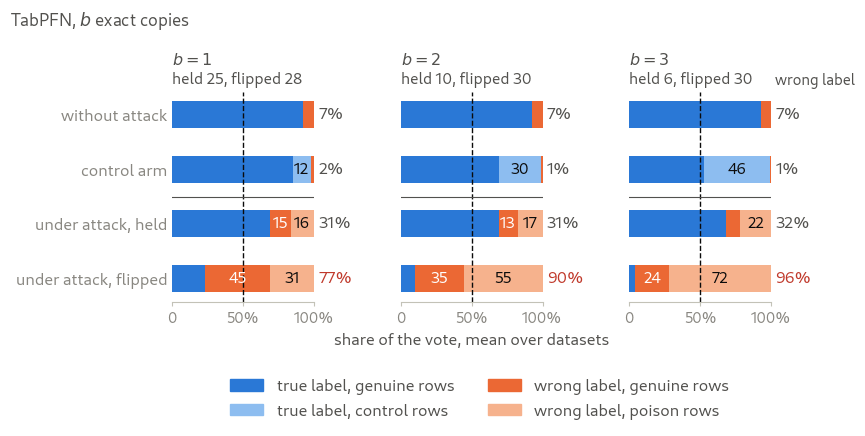

-> gen/fig_vote.pdf


In [17]:
WAHR, WAHR_HELL, GIFT, GIFT_HELL = "#2a78d6", "#8dbdf0", "#eb6834", "#f6b28d"
HELLBLAU = "#f1f6fc"


def gruppen(model, b):
    """Attacked target rows of one model at budget b, split into held (0) and flipped (1); each group over every
    dataset with at least MIN_ZIEL target rows in that group (the same datasets as the group means of app_pfn_gegen)."""
    x = CC[(CC.model == model) & (CC.b == b)]
    n = x.groupby(["dataset", "flipped"]).size().unstack(fill_value=0)
    return {grp: x[(x.flipped == flag) & x.dataset.isin(n.index[n.get(flag, 0) >= MIN_ZIEL])]
            for grp, flag in (("held", 0), ("flipped", 1))}


VOTE_DS = {}                                      # per model: per dataset the mean weights per condition (table of the vote)


def fig_vote(model, b, datei):
    """One row per condition: without attack and control arm over ALL attacked target rows, under attack per group
    (outcome under attack). The shares of the vote (per dataset the mean, then the mean over the datasets)."""
    teile = gruppen(model, b)
    alle = CC[(CC.model == model) & (CC.b == b)]
    # (label, rows, the four parts of the vote: true genuine, true inserted, wrong genuine, poison)
    zeilen = [("without attack, all target rows", alle, ("a_T0", None, "a_F0", None)),
              ("control arm, all target rows", alle, ("a_T_c", "a_copy_c", "a_F_c", None)),
              (f"under attack, held ({teile['held'].dataset.nunique()} datasets)", teile["held"], ("a_T", None, "a_F", "a_copy")),
              (f"under attack, flipped ({teile['flipped'].dataset.nunique()} datasets)", teile["flipped"],
               ("a_T", None, "a_F", "a_copy"))][::-1]                             # bottom to top
    fig, bx = plt.subplots(figsize=(7.4, 3.4))
    farben = (WAHR, WAHR_HELL, GIFT, GIFT_HELL)
    werte = []
    bx.set_xlim(0, 1); bx.set_yticks(range(len(zeilen)), [z[0] for z in zeilen]); bx.grid(visible=False)
    bx.set_facecolor("white"); bx.spines[["top", "right"]].set_visible(False)
    for pos, (name, sub, spalten) in enumerate(zeilen):
        anteile = [sub.groupby("dataset")[c].mean().mean() if c else 0.0 for c in spalten]
        VOTE_DS.setdefault(model, []).append(pd.DataFrame({k: sub.groupby("dataset")[c].mean() for k, c in zip(("a_T", "a_C", "a_F", "a_P"), spalten) if c})
                       .rename_axis("dataset").reset_index().assign(condition=name.split(" (")[0]))
        links = 0.0
        for wert, farbe in zip(anteile, farben):
            if wert > 0:
                bx.barh(pos, wert, left=links, color=farbe, height=0.5)
                if wert >= 0.05 and farbe != WAHR:
                    bx.text(links + wert / 2, pos, f"{100 * wert:.0f}", ha="center", va="center", fontsize=8.5,
                            color="white" if farbe == GIFT else TINTE)
            links += wert
        falsch = anteile[2] + anteile[3]
        bx.text(1.02, pos, f"{100 * falsch:.0f}%", va="center", fontsize=9,
                color="#c0392b" if falsch > 0.5 else TINTE2, transform=bx.get_yaxis_transform())
        werte.append(dict(condition=name, datasets=sub.dataset.nunique(), true_genuine=anteile[0],
                          true_inserted=anteile[1], wrong_genuine=anteile[2], wrong_poisoned=anteile[3], wrong_label=falsch))
    bx.axvline(0.5, color=TINTE, ls="--", lw=1); bx.axhline(1.5, color=TINTE2, lw=0.8)
    bx.text(1.02, len(zeilen) - 0.45, "wrong label", fontsize=8.5, color=TINTE2, transform=bx.get_yaxis_transform())
    bx.set_xticks([0, 0.5, 1], ["0", "50%", "100%"])
    bx.set_xlabel("share of the vote, mean over datasets")
    griffe = [plt.Rectangle((0, 0), 1, 1, color=f) for f in farben]
    fig.legend(griffe, ["true label, genuine rows", "true label, control rows", "wrong label, genuine rows",
                        "wrong label, poison rows"], loc="lower center", ncol=2, bbox_to_anchor=(0.55, -0.22))
    fig.suptitle(f"{LAB[model]}, {b} exact cop{'y' if b == 1 else 'ies'}", x=0.02, ha="left", fontsize=10, color=TINTE2)
    if datei:
        sichern(fig, datei)
    else:
        plt.close(fig)
    return pd.DataFrame(werte)


FIG_VOTE_B = (1, 2, 3)                       # four and five poison rows in the table and the CSV


def fig_vote_neben(model, budgets, datei):
    # per group the same target rows without and under attack; the control arm is left to the tables
    namen = ["held, without attack", "held, under attack", "flipped, without attack", "flipped, under attack"][::-1]
    fig, axes = plt.subplots(1, len(budgets), figsize=(2.9 * len(budgets), 3.6), sharey=True)
    farben = (WAHR, WAHR_HELL, GIFT, GIFT_HELL)
    for bx, b in zip(axes, budgets):
        teile, alle = gruppen(model, b), CC[(CC.model == model) & (CC.b == b)]
        zeilen = [(teile["held"], ("a_T0", None, "a_F0", None)), (teile["held"], ("a_T", None, "a_F", "a_copy")),
                  (teile["flipped"], ("a_T0", None, "a_F0", None)), (teile["flipped"], ("a_T", None, "a_F", "a_copy"))][::-1]
        bx.set_xlim(0, 1); bx.set_yticks(range(len(zeilen)), namen); bx.grid(visible=False)
        bx.set_facecolor("white"); bx.spines[["top", "right"]].set_visible(False)
        for pos, (sub, spalten) in enumerate(zeilen):
            anteile = [sub.groupby("dataset")[c].mean().mean() if c else 0.0 for c in spalten]
            links = 0.0
            for wert, farbe in zip(anteile, farben):
                if wert > 0:
                    bx.barh(pos, wert, left=links, color=farbe, height=0.5)
                    if wert >= 0.1 and farbe != WAHR:
                        bx.text(links + wert / 2, pos, f"{100 * wert:.0f}", ha="center", va="center", fontsize=11.5,
                                color="white" if farbe == GIFT else TINTE)
                links += wert
            falsch = anteile[2] + anteile[3]
            bx.text(1.03, pos, f"{100 * falsch:.0f}%", va="center", fontsize=12,
                    color="#c0392b" if falsch > 0.5 else TINTE2, transform=bx.get_yaxis_transform())
        bx.axvline(0.5, color=TINTE, ls="--", lw=1); bx.axhline(1.5, color=TINTE2, lw=0.8)
        bx.set_xticks([0, 0.5, 1], ["0", "50%", "100%"]); bx.tick_params(axis="x", labelsize=11); bx.tick_params(axis="y", labelsize=12)
        bx.set_title(f"$b = {b}$\nheld {teile['held'].dataset.nunique()}, flipped {teile['flipped'].dataset.nunique()}",
                     loc="left", fontsize=11.5, color=TINTE2)
    axes[len(axes) // 2].set_xlabel("share of the vote, mean over datasets", fontsize=12)
    axes[-1].text(1.03, len(namen) - 0.3, "wrong\nlabel", fontsize=11, color=TINTE2, va="bottom", transform=axes[-1].get_yaxis_transform())
    griffe = [plt.Rectangle((0, 0), 1, 1, color=f) for f in (WAHR, GIFT, GIFT_HELL)]
    fig.legend(griffe, ["true label", "wrong label, genuine rows", "wrong label, poison rows"], loc="lower center", ncol=3,
               bbox_to_anchor=(0.55, -0.12), fontsize=12)
    fig.suptitle(f"{LAB[model]}, $b$ exact copies", x=0.01, ha="left", fontsize=12.5, color=TINTE2)
    fig.tight_layout(w_pad=3.0)
    sichern(fig, datei)


def vote_tabelle(VOTE, name, ds):
    """The vote of the figure as a table: per condition the mean weights (sum 1) and the shares in percent (sum 100)."""
    V = VOTE.assign(condition=VOTE.condition.str.split(" \\(").str[0]).set_index("condition")
    V = V.loc[["without attack, all target rows", "control arm, all target rows", "under attack, held", "under attack, flipped"]]
    rows = [r"\multicolumn{8}{@{}l}{\textit{weights, mean over the datasets, sum 1}}"]
    for cond, r in V.iterrows():
        w = [r.true_genuine, r.wrong_genuine, r.wrong_poisoned, r.true_inserted]
        rows.append(f"{cond} & {int(r.datasets)} & " + " & ".join("--" if v == 0 else f"${v:.3f}$" for v in w) + f" & ${sum(w):.3f}$ & ${r.wrong_label:.3f}$")
    rows.append(r"\midrule \multicolumn{8}{@{}l}{\textit{shares in percent, sum 100}}")
    for cond, r in V.iterrows():
        w = [r.true_genuine, r.wrong_genuine, r.wrong_poisoned, r.true_inserted]
        rows.append(f"{cond} & {int(r.datasets)} & " + " & ".join("--" if v == 0 else f"${100 * v:.0f}$" for v in w) + f" & ${100 * sum(w):.0f}$ & ${100 * r.wrong_label:.0f}$")
    write(name, tabular("@{}lrcccccc@{}", r"condition & DS & $a_{T,G}$ & $a_{F,G}$ & $a_{F,P}$ & $a_{T,C}$ & sum & $\pi_F = a_F$", rows, wide=False),
              V.reset_index(), ds=ds)


# Number of copies for this figure: set it here and rerun this cell (every model of VOTE_B that has the vote there).
FIG_B = 1
VOTES = {}
for model in VOTE_B:
    if FIG_B in VOTE_B[model]:
        tag = VOTE_TAG[model]
        VOTES[model] = fig_vote(model, FIG_B, None)
        display(VOTES[model].round(3))
        fig_vote_neben(model, [b for b in FIG_VOTE_B if b in VOTE_B[model]], "fig_vote" if tag == "pfn" else f"fig_vote_{tag}")


## Numbers for the text

Writes `gen/zahlen.tex`: LaTeX macros the manuscript uses instead of typed numbers, e.g. `\\zICLasrZwei` (mean ASR
of TabICL at two copies). When the data change, rerunning this notebook updates every number in the text.

In [18]:
# Macro names: \z<model><quantity><budget as a word>, e.g. \zPFNasrZwei.
TAG = {"tabicl-n8": "ICL", "tabpfn35-n8": "PFN", "catboost": "CAT"}
WORT = {1: "Eins", 2: "Zwei", 3: "Drei", 4: "Vier", 5: "Fuenf"}
lines = [f"\\newcommand{{\\zDS}}{{{len(DS)}}}",
         f"\\newcommand{{\\zDupDS}}{{{int((META.dup_targets > 0).sum())}}}",
         f"\\newcommand{{\\zDupMax}}{{{int(META.dup_max.max())}}}",
         f"\\newcommand{{\\zGanzDS}}{{{int((META.int_features > 0).sum())}}}"]
for m, lab in MODELS:
    t = TAG[m]
    lines.append(f"\\newcommand{{\\z{t}auc}}{{{AUCC.loc[m].reindex(DS).mean():.3f}}}")
    for b in BUDGETS:
        S = sel(m, b)
        w = WORT[b]
        lines += [f"\\newcommand{{\\z{t}asr{w}}}{{{100 * S.ASR.mean():.0f}}}",
                  f"\\newcommand{{\\z{t}asrSD{w}}}{{{100 * S.ASR.std(ddof=1):.0f}}}",
                  f"\\newcommand{{\\z{t}halb{w}}}{{{int((S.ASR >= 0.5).sum())}}}",
                  f"\\newcommand{{\\z{t}neunzig{w}}}{{{int((S.ASR >= 0.9).sum())}}}",
                  f"\\newcommand{{\\z{t}zehn{w}}}{{{int((S.ASR < 0.1).sum())}}}",
                  f"\\newcommand{{\\z{t}asrMin{w}}}{{{100 * S.ASR.min():.0f}}}",
                  f"\\newcommand{{\\z{t}asrMax{w}}}{{{100 * S.ASR.max():.0f}}}",
                  f"\\newcommand{{\\z{t}kontrolle{w}}}{{{100 * S.ASR_c.mean():.1f}}}"]
    bm = BS[BS.model == m].groupby("dataset").bstar.apply(bstern_med)
    lines.append(f"\\newcommand{{\\z{t}bsternMin}}{{{bstern_txt(bm.min()).strip('$')}}}")
    lines.append(f"\\newcommand{{\\z{t}bsternMax}}{{{bstern_txt(bm.max()).strip('$')}}}")
# Further numbers of the text, read from the tables of the cells above (gen/csv) or computed as there.
# Values are plain text (no $); signed values carry their sign and belong inside $...$ in the manuscript.
import re

def mac(name, value):
    assert re.fullmatch(r"z[A-Za-z]+", name), name
    lines.append(f"\\newcommand{{\\{name}}}{{{value}}}")


def f(x, d):
    return f"{x:.{d}f}"


def sf(x, d):
    return f"{x:+.{d}f}"


def liste(namen):
    namen = list(namen)
    return "--" if not namen else namen[0] if len(namen) == 1 else ", ".join(namen[:-1]) + " und " + namen[-1]


def rd(name):
    return pd.read_csv(CSV / f"{name}.csv")


def kopf(ds):
    return "".join(w[:1].upper() + w[1:] for w in re.split(r"[^A-Za-z]+", ds) if w)


namen = {ds: kopf(ds) for ds in DS}
assert len(set(namen.values())) == len(namen), "two datasets share a macro name"
mac("zZiele", f"{int(META.targets.sum()):,}")
for m, lab in MODELS:                                     # A.1: the AUC on hill-valley, where CatBoost falls behind
    mac(f"z{TAG[m]}aucHillValley", f(AUCC.loc[m]["hill-valley"], 3))
for m, lab in TFMS:                                       # Section 3.2: about half of the AUC gap to CatBoost comes from hill-valley
    gap = (AUCC.loc[m] - AUCC.loc["catboost"]).reindex(DS)
    assert 0.4 <= gap["hill-valley"] / len(DS) / gap.mean() <= 0.6, (lab, gap["hill-valley"] / len(DS) / gap.mean())
mac("zDupZielzeilen", int(META.dup_targets.sum()))
for m, lab in MODELS:
    t = TAG[m]
    r_ = [int(f(100 * sel(m, b).ASR.mean(), 0)) for b in BUDGETS]                 # the rounded means of the ASR figure
    mac(f"z{t}zuwachsZwei", r_[1] - r_[0]); mac(f"z{t}zuwachsDrei", r_[2] - r_[1]); mac(f"z{t}zuwachsRest", r_[-1] - r_[2])
    a_ = pd.concat([sel(m, b).ASR.rename(b) for b in BUDGETS], axis=1)
    sinkt = int((a_.diff(axis=1).iloc[:, 1:] < -1e-12).any(axis=1).sum())           # datasets on which the ASR falls with a further copy
    assert sinkt == 0, f"{lab}: the ASR falls with a further copy on {sinkt} datasets; Sections 3.1 and 3.2 say on none"
    # ASR at every budget per dataset, e.g. \zCATasrEinsPhoneme; the datasets below 10 % at one copy
    for b in BUDGETS:
        S = sel(m, b)
        for ds in DS:
            mac(f"z{t}asr{WORT[b]}{namen[ds]}", f(100 * S.ASR[ds], 0))
    S = sel(m, 1)
    mac(f"z{t}zehnListeEins", liste(tex_name(ds) for ds in DS if S.ASR[ds] < 0.1))
    # attacked target rows, flips in the control arm (all budgets), target rows that hold five copies,
    # with and without an exact duplicate carrying the true label in the clean context
    xa = CC[CC.model == m]                                   # attacked target rows (per budget the same rows)
    mac(f"z{t}angegriffen", f"{int((xa.b == 1).sum()):,}")
    mac(f"z{t}kontrolleKippt", int(xa.flipped_c.sum()))
    h = CC[(CC.model == m) & (CC.b == max(BUDGETS)) & (CC.flipped == 0)].drop(columns="n_dup0", errors="ignore").merge(clean[K + ["n_dup0"]], on=K)
    mac(f"z{t}haeltFuenf", len(h))
    mac(f"z{t}haeltFuenfDup", int((h.n_dup0 > 0).sum()))
    mac(f"z{t}haeltFuenfOhne", int((h.n_dup0 == 0).sum()))
    # minority against majority class
    kl = rd("app_klassen")
    kl = kl[kl.model == lab].set_index("b")
    for b in BUDGETS:
        mac(f"z{t}minder{WORT[b]}", f(100 * kl.minority[b], 0))
        mac(f"z{t}mehr{WORT[b]}", f(100 * kl.majority[b], 0))
        mac(f"z{t}minderHoeher{WORT[b]}", int(kl.hi[b])); mac(f"z{t}minderNiedriger{WORT[b]}", int(kl.lo[b]))
        mac(f"z{t}minderDS{WORT[b]}", int(kl.n_both[b]))
    if m == "tabpfn35-n8":                                    # Section 3.1 names one number of datasets for both TFMs
        k2 = rd("app_klassen").query("b == 1").set_index("model").n_both
        assert k2["TabICL"] == k2["TabPFN"], k2
    a_ = SI[(SI.model == lab) & (SI.b == 1)].iloc[0]                                  # AUC of the certainty without attack for the flip, one copy
    mac(f"z{t}aucSicherheitEins", f(a_.auc_mean, 2)); mac(f"z{t}aucSicherheitSDEins", f(a_.auc_sd, 2))
    mac(f"z{t}aucSicherheitDSEins", int(a_.auc_ds)); mac(f"z{t}aucSicherheitHoeherEins", int(a_.auc_hi))
    # confidence of the flipped target rows (as in B.2): per dataset the median, then the mean
    for b in BUDGETS:
        x = CC[(CC.model == m) & (CC.b == b) & (CC.flipped == 1)]
        g = x.groupby("dataset").agg(n=("pi_F", "size"), p0=("pi_F0", "median"), p=("pi_F", "median"))
        g = g[g.n >= MIN_ZIEL]
        mac(f"z{t}pFnull{WORT[b]}", f(g.p0.mean(), 2))
        mac(f"z{t}pF{WORT[b]}", f(g.p.mean(), 2))
        mac(f"z{t}pFnullSD{WORT[b]}", f(g.p0.std(ddof=1), 2))
        mac(f"z{t}pFSD{WORT[b]}", f(g.p.std(ddof=1), 2))
        h = CC[(CC.model == m) & (CC.b == b) & (CC.flipped == 0)]              # the held target rows, the same rule
        gh = h.groupby("dataset").agg(n=("pi_F", "size"), p0=("pi_F0", "median"), p=("pi_F", "median"))
        gh = gh[gh.n >= MIN_ZIEL]
        if len(gh):
            mac(f"z{t}pFnullGehalten{WORT[b]}", f(gh.p0.mean(), 2)); mac(f"z{t}pFGehalten{WORT[b]}", f(gh.p.mean(), 2))
            mac(f"z{t}pFnullGehaltenSD{WORT[b]}", f(gh.p0.std(ddof=1), 2)); mac(f"z{t}pFGehaltenSD{WORT[b]}", f(gh.p.std(ddof=1), 2))
        s9 = x[x.dataset.isin(g.index)].groupby("dataset").pi_F.apply(lambda s: (s >= 0.9).mean())
        mac(f"z{t}sicher{WORT[b]}", f(100 * s9.mean(), 0))              # per dataset the share, then the mean (as in C.2)
        s1 = x[x.dataset.isin(g.index)].groupby("dataset").pi_F0.apply(lambda s: (s <= 0.1).mean())     # the same rows without attack (B3, left)
        mac(f"z{t}sicherNull{WORT[b]}", f(100 * s1.mean(), 0))
    # remaining test rows: changed predictions (range over the budgets), largest AUC shift of one dataset
    a = rd("app_ausserhalb")
    a = a[a.model == lab]
    for b in BUDGETS:
        mac(f"z{t}co{WORT[b]}", f(a.set_index("b").co[b], 1)); mac(f"z{t}coC{WORT[b]}", f(a.set_index("b").co_c[b], 1))
    mac(f"z{t}coMin", f(a.co.min(), 1)); mac(f"z{t}coMax", f(a.co.max(), 1))
    mac(f"z{t}coCMin", f(a.co_c.min(), 1)); mac(f"z{t}coCMax", f(a.co_c.max(), 1))
    mac(f"z{t}aucMax", f(a.groesste.abs().max(), 3))                  # rounded as in Table B6
mac("zTFMaucMax", f(rd("app_ausserhalb").query("model != 'CatBoost'").groesste.abs().max(), 3))
gt = rd("app_gepaart_tfm").set_index("b")                       # TabICL against TabPFN: Spearman of the two ASR series over the datasets
mac("zTFMrhoEins", f(gt.rho[1], 2)); mac("zTFMrhoMin", f(np.floor(100 * gt.rho.min()) / 100, 2))
mac("zTFMdiffEins", f(abs(gt["diff"][1]), 1)); mac("zTFMdiffZwei", f(abs(gt["diff"][2]), 1))   # TabPFN above TabICL at one and two copies (pp)
gc = rd("app_gepaart_cat")                                      # each TFM against CatBoost: level (difference) and order (Spearman)
for pair_, tag_ in (("TabICL-CatBoost", "ICL"), ("TabPFN-CatBoost", "PFN")):
    g1_, g2_, g3_ = (gc[(gc.pair == pair_) & (gc.b == b_)].iloc[0] for b_ in (1, 2, 3))
    mac(f"zCATrho{tag_}Eins", f(g1_.rho, 2)); mac(f"zCATrho{tag_}Zwei", f(g2_.rho, 2)); mac(f"zCATrho{tag_}Drei", f(g3_.rho, 2))
    mac(f"zCATdiff{tag_}Eins", f(abs(g1_["diff"]), 1)); mac(f"zCATdiff{tag_}Drei", f(abs(g3_["diff"]), 1))
    mac(f"zCATciLo{tag_}Eins", f(g1_.ci_lo, 1).replace("-", "$-$")); mac(f"zCATciHi{tag_}Eins", f(g1_.ci_hi, 1).replace("-", "$-$"))   # TFM minus CatBoost, 95 % interval
    mac(f"zCAThoeher{tag_}Eins", int(g1_.hi)); mac(f"zCATniedriger{tag_}Eins", int(g1_.lo))
assert (sel("catboost", 1).ASR < 0.1).sum() == 0, "Section 3.2 says: CatBoost has no dataset with an ASR below 10 % at one copy"
assert int(CC[CC.model == "catboost"].flipped_c.sum()) == 0, "Section 3.2 says: no target row of CatBoost flips in the control arm"

# paired comparisons; diff is the first model minus the second, in pp
for paar, tag in (("TabICL-TabPFN", "ICLPFN"), ("TabICL-CatBoost", "ICLCAT"), ("TabPFN-CatBoost", "PFNCAT")):
    g = pd.concat([rd("app_gepaart_tfm"), rd("app_gepaart_cat")])
    g = g[g.pair == paar].set_index("b")
    for b in BUDGETS:
        w = WORT[b]
        mac(f"z{tag}diff{w}", sf(g["diff"][b], 1)); mac(f"z{tag}diffBetrag{w}", f(abs(g["diff"][b]), 1))
        mac(f"z{tag}hoeher{w}", int(g.hi[b])); mac(f"z{tag}niedriger{w}", int(g.lo[b]))
        mac(f"z{tag}rho{w}", f(g.rho[b], 2))
    mac(f"z{tag}rhoMin", f(g.rho.min(), 2)); mac(f"z{tag}rhoMax", f(g.rho.max(), 2))
    mac(f"z{tag}diffBetragMax", f(g["diff"].abs().max(), 1))          # the largest gap over the budgets
    r2 = g.rho[g.index >= 2]                                          # Section 3.1: rho at two to five copies
    mac(f"z{tag}rhoMinAbZwei", f(r2.min(), 2)); mac(f"z{tag}rhoMaxAbZwei", f(r2.max(), 2))

GEGEN = {"a_copy": "aP", "a_F": "aF", "a_T": "aT"}
for model in VOTE_B:
    m, tabelle, spalten = TAG[model], f"app_{VOTE_TAG[model]}_gegen", GEGEN
    g = rd(tabelle)
    g1 = g[g.b == 1].set_index("col")
    mac(f"z{m}gegenDS", int(g1.DS.iloc[0]))
    if (g.b == 3).any():
        mac(f"z{m}gegenDSDrei", int(g[g.b == 3].DS.iloc[0]))
    for c, kurz in spalten.items():
        r = g1.loc[c]
        d, fm = 3, f                                   # the weights are unsigned
        mac(f"z{m}gegen{kurz}Gekippt", fm(r.flipped, d)); mac(f"z{m}gegen{kurz}Gehalten", fm(r.held, d))
        mac(f"z{m}gegen{kurz}GekipptSD", f(r.flipped_sd, d)); mac(f"z{m}gegen{kurz}GehaltenSD", f(r.held_sd, d))
        # paired difference flipped minus held over the datasets (mean, SD) and the sign count
        mac(f"z{m}gegen{kurz}Diff", sf(r.d_mean, d)); mac(f"z{m}gegen{kurz}DiffSD", f(r.d_sd, d))
        mac(f"z{m}gegen{kurz}Hoeher", int(r.hi)); mac(f"z{m}gegen{kurz}Niedriger", int(r.lo))
        if ((g.b == 2) & (g.col == c)).any():
            r2 = g[(g.b == 2) & (g.col == c)].iloc[0]
            mac(f"z{m}gegen{kurz}DSZwei", int(r2.DS))
            mac(f"z{m}gegen{kurz}GekipptZwei", fm(r2.flipped, d)); mac(f"z{m}gegen{kurz}GehaltenZwei", fm(r2.held, d))
            mac(f"z{m}gegen{kurz}HoeherZwei", int(r2.hi)); mac(f"z{m}gegen{kurz}NiedrigerZwei", int(r2.lo))
# The weight of the genuine wrong-label rows without attack, over all attacked target rows (from the vote tables);
# in the control arm: \zPFNaFKontrolleEins below
for model in VOTE_B:
    t = TAG[model]
    pb0 = rd(f"app_{VOTE_TAG[model]}_b")
    mac(f"z{t}aFnullAlleEins", f(pb0[pb0.arm == "clean"].a_F.iloc[0], 3))
    mac(f"z{t}aTnullAlleEins", f(pb0[pb0.arm == "clean"].a_T.iloc[0], 3))
    # the same weight without attack for the later flipped and the held target rows (Appendix E.3, one copy)
    af_ = rd(f"app_{VOTE_TAG[model]}_aF"); af_ = af_[af_.b == 1].set_index("comparison")
    mac(f"z{t}aFnullGekipptEins", f(af_.a_F0["flipped"], 3)); mac(f"z{t}aFnullGehaltenEins", f(af_.a_F0["held"], 3))
# Figure of the vote (fig_vote): the shares of the vote as the figure prints them (mean over datasets)
for model in VOTE_B:
    t = TAG[model]
    if model not in VOTES:
        continue
    V_ = VOTES[model]
    _vote = lambda prefix: V_[V_.condition.str.startswith(prefix)].iloc[0]
    for key, prefix in (("Null", "without attack"), ("Kontrolle", "control arm"), ("Gehalten", "under attack, held"), ("Gekippt", "under attack, flipped")):
        mac(f"z{t}figpF{key}", f(100 * _vote(prefix).wrong_label, 0))
    mac(f"z{t}figaFGekippt", f(100 * _vote("under attack, flipped").wrong_genuine, 0))
    mac(f"z{t}figaPGekippt", f(100 * _vote("under attack, flipped").wrong_poisoned, 0))
    mac(f"z{t}figaFKontrolle", f(100 * _vote("control arm").wrong_genuine, 0))
    mac(f"z{t}figaCKontrolle", f(100 * _vote("control arm").true_inserted, 0))
# TabPFN: pi_F = a_F + a_P per target row (largest deviation over all attacked cells)
P_ = CC.model == "tabpfn35-n8"
dev = (CC.loc[P_, "pi_F"] - CC.loc[P_, "a_F"] - CC.loc[P_, "a_copy"]).abs().max()
e = int(np.floor(np.log10(dev)))
mac("zPFNidentMax", f"${dev / 10 ** e:.1f} \\cdot 10^{{{e}}}$")
# the imbalanced datasets of B.4, and Pulsar in 4.3 (from app_innen_ds, b = 1)
mac("zKlassenDS", int((META.minority < 0.4).sum()))
pu = rd("app_innen_ds").set_index("dataset").loc["Pulsar-Dataset-HTRU2"]
mac("zPulsarAP", f(pu.aP_PFN, 2))
# The poison row alone against one half (flipped target rows), and the vote per budget: the models with the vote
for model in VOTE_B:
    t = TAG[model]
    ah = rd(f"app_{VOTE_TAG[model]}_aP_halb").set_index("b")
    mac(f"z{t}aPhalbDSEins", int(ah.DS[1])); mac(f"z{t}aPhalbUnterEins", int(ah.lo[1]))
    # a_F against without attack (app_<model>_aF): per comparison at one copy the datasets and the sign counts
    af = rd(f"app_{VOTE_TAG[model]}_aF")
    for r in af[af.b == 1].itertuples():
        g = {"flipped": "Gekippt", "held": "Gehalten", "control": "Kontrolle"}[r.comparison]
        mac(f"z{t}aFtest{g}DSEins", int(r.DS)); mac(f"z{t}aFtest{g}HoeherEins", int(r.hi)); mac(f"z{t}aFtest{g}GleichEins", int(r.eq))
        mac(f"z{t}aFtest{g}NiedrigerEins", int(r.lo))
        mac(f"z{t}aFtest{g}NullEins", f(r.a_F0, 3)); mac(f"z{t}aFtest{g}Eins", f(r.a_F, 3))     # a_F,0 and a_F on the same rows
    a1 = af[af.b == 1].set_index("comparison")                        # Section 3.3.2: a_F,G rises in every dataset under attack, falls in the control arm
    assert (a1.hi[["flipped", "held"]] == a1.DS[["flipped", "held"]]).all() and a1.lo["control"] == a1.DS["control"], a1
    # the copy as the strongest row (rank 1 by weight in every member) over ALL attacked target rows, per dataset the mean
    xs = CC[(CC.model == model) & (CC.b == 1)]
    mac(f"z{t}staerksteAlleEins", f(100 * xs.groupby("dataset").strongest.mean().mean(), 1))
    pb = rd(f"app_{VOTE_TAG[model]}_b").set_index(["arm", "b", "group"])
    fl = pb.loc["attack"].xs("flipped", level="group")                # Section 3.3.2: with more poison rows the poison rows take over
    assert fl.a_copy.is_monotonic_increasing and fl.a_F.is_monotonic_decreasing, fl[["a_copy", "a_F"]]
    assert fl.a_copy[2] > 0.5, "Section 3.3.2: at two poison rows a_F,P of the flipped is at least half"
    att, ctl = pb.loc["attack"], pb.loc["control"]
    for b in VOTE_B[model]:
        w = WORT[b]
        for grp, gw in (("flipped", "Gekippt"), ("held", "Gehalten")):
            if (b, grp) in att.index:
                pg = gruppen(model, b)["flipped" if grp == "flipped" else "held"]   # the paired basis
                if pg.dataset.nunique():
                    mac(f"z{t}staerkste{gw}{w}", f(100 * pg.groupby("dataset").strongest.mean().mean(), 1))
                    mac(f"z{t}staerkste{gw}{w}Ganz", f(100 * pg.groupby("dataset").strongest.mean().mean(), 0))   # whole percent for the text
                mac(f"z{t}aP{gw}{w}", f(att.a_copy[(b, grp)], 3))
                mac(f"z{t}aPmax{gw}{w}", f(att.a_copy_max[(b, grp)], 3))
        mac(f"z{t}aCKontrolle{w}", f(ctl.a_copy[(b, "all")], 3))
        mac(f"z{t}aFKontrolle{w}", f(ctl.a_F[(b, "all")], 3))
        mac(f"z{t}aPAlle{w}", f(att.a_copy[(b, "all")], 2))
        mac(f"z{t}aFAlle{w}", f(att.a_F[(b, "all")], 2)); mac(f"z{t}aTAlle{w}", f(att.a_T[(b, "all")], 2))

# At the largest budget: datasets on which not every attacked target row flips, and the smallest ASR (rounded down)
B_MAX = max(BUDGETS)
for m in ("tabicl-n8", "tabpfn35-n8"):
    mac(f"z{TAG[m]}nichtAlleFuenf", int((sel(m, B_MAX).ASR.dropna() < 1).sum()))
mac("zTFMasrMinFuenf", f(np.floor(100 * min(sel(m, B_MAX).ASR.min() for m in ("tabicl-n8", "tabpfn35-n8"))), 0))

# 4.2: the poison row is the most attended row for most flipped target rows at every budget (smallest share, rounded down)
# on the paired basis of 3.3 (both groups with >= MIN_ZIEL rows), every budget that has such datasets
st = {b: gruppen("tabpfn35-n8", b)["flipped"] for b in (1, 2)}    # the budgets with at least five such datasets
st = {b: g.groupby("dataset").strongest.mean().mean() for b, g in st.items() if g.dataset.nunique()}
print("strongest, flipped, paired basis:", {b: round(100 * v, 1) for b, v in st.items()})
mac("zPFNstaerksteGekipptMin", f(np.floor(100 * min(st.values())), 0))

rp = rd("app_kontrolle_reparatur")                       # Section 4.2: the copy with the true label corrects wrong predictions
for m, lab in MODELS:
    r1 = rp[rp.model == lab].set_index("b")
    mac(f"z{TAG[m]}reparaturEins", f(100 * r1.corrected_mean[1], 0)); mac(f"z{TAG[m]}reparaturDrei", f(100 * r1.corrected_mean[3], 0))
    assert r1.pi_F0[1] > 0.5, lab                          # pi_F,0 of wrong rows above one half, as it must be

# Section 3.1 in words (TabICL and TabPFN, one poison row): "most" flipped target rows were correct with pi_F0 <= 0.1,
# "about a quarter" end with pi_F >= 0.9, the second poison row adds "about 25" percentage points
werte = {l.split("}{")[0].replace("\\newcommand{\\", ""): l.split("}{")[1].rstrip("}") for l in lines}
for t_ in ("ICL", "PFN"):
    assert float(werte[f"z{t_}sicherNullEins"]) > 50 and 20 <= float(werte[f"z{t_}sicherEins"]) <= 30, t_
    assert abs(float(werte[f"z{t_}zuwachsZwei"]) - 25) <= 2, t_

# Keep only the macros a manuscript version uses (paper/ and paper/archiv/): a macro appears as soon
# as the text names it and this cell runs.
TEXT = "".join(p.read_text() for d in (GEN.parent, GEN.parent / "archiv") for p in sorted(d.glob("ticp_alparslan_v*.tex")) + sorted(d.glob("anhang*.tex")))
alle = len(lines)
lines = [l for l in lines if re.search(re.escape(l.split("}{")[0].replace("\\newcommand{", "")) + r"(?![A-Za-z])", TEXT)]
print(f"{len(lines)} of {alle} macros are used and written")
(GEN / "zahlen.tex").write_text("\n".join(lines) + "\n")
display(pd.DataFrame([l.replace("\\newcommand{\\", "").rstrip("}").split("}{") for l in lines],
                     columns=["macro", "value"]))

strongest, flipped, paired basis: {1: np.float64(83.2), 2: np.float64(83.3)}


17 of 1162 macros are used and written


,macro,value
0,zDS,30
1,zDupDS,4
2,zDupMax,708
3,zICLauc,0.958
4,zICLasrEins,53
5,zICLasrDrei,94
6,zPFNauc,0.962
7,zPFNasrEins,65
8,zPFNasrDrei,97
9,zCATauc,0.930


In [19]:
# Reproducibility: packages, checkpoints, seeds, hardware and run time, from the run records of measurements.parquet
import json as _json
import pyarrow.parquet as _pq
from core import config as _C
runs = pd.DataFrame(_json.loads(_pq.read_schema(DATA).metadata[b"runs"]))
runs["started"], runs["written"] = pd.to_datetime(runs.started), pd.to_datetime(runs.written)
# checkpoints as loaded by the runs (core/models.py checks the TabPFN architecture after every fit)
CKPT = {"tabicl-n8": "tabicl-classifier-v2-20260212.ckpt", "tabpfn35-n8": "tabpfn-v3.5-20260909.safetensors (TabPFNV3p5)",
        "catboost": "defaults, no checkpoint"}
PKG = {"tabicl-n8": "tabicl", "tabpfn35-n8": "tabpfn", "catboost": "catboost"}
ALL = pd.read_parquet(DATA, columns=["model", "arm", "dataset", "fold"])
rows, out = [], []
for m, lab in MODELS:
    r = runs[(runs.model == m) & runs.packages.notna()]       # the records of the runs
    pk = dict(r.packages.iloc[-1])
    if m == "catboost":
        pk["torch"] = "--"                                   # CatBoost does not use torch
    h = r.groupby("run").apply(lambda g: (g.written.max() - g.started.min()).total_seconds() / 3600).sum()
    a = ALL[ALL.model == m]
    fits = int((a.arm != "clean").sum() + a[["dataset", "fold"]].drop_duplicates().shape[0])
    rows.append(f"{lab} & {PKG[m]} {pk[PKG[m]]} & {CKPT[m].replace('_', chr(92) + '_')} & {pk.get('torch', '--')} & "
                f"{len(a):,} & " + (f"{fits:,}" if m == "catboost" else "--"))
    out.append(dict(model=lab, package=pk[PKG[m]], checkpoint=CKPT[m], torch=pk.get("torch"), cells=len(a),
                    fits=fits if m == "catboost" else None, hours=h))
# the random forest and the logistic regression (runs/reference_models.py, environment tabfm_cu130): their result file
# keeps no run record, so the version of scikit-learn comes from the environment file
REF = pd.read_parquet(DATA.parent / "reference_models.parquet", columns=["model", "arm", "dataset", "fold"])
_skl = next(l.split("==")[1].strip() for l in (DATA.parent.parent / "environment" / "tabfm_cu130.txt").read_text().splitlines()
            if l.startswith("scikit-learn=="))
for m, lab in (("random-forest", "Random forest"), ("logistic-regression", "Logistic regression")):
    a = REF[REF.model == m]
    fits = int((a.arm != "clean").sum() + a[["dataset", "fold"]].drop_duplicates().shape[0])
    rows.append(f"{lab} & scikit-learn {_skl} & defaults, no checkpoint & -- & {len(a):,} & {fits:,}")
    out.append(dict(model=lab, package=_skl, checkpoint="defaults, no checkpoint", torch=None, cells=len(a), fits=fits, hours=None))
write("app_repro", tabular("@{}lllrrr@{}", r"Model & package & checkpoint & torch & cells & fits", rows),      # the hours stay in the CSV
      pd.DataFrame(out))
# the seeds as Appendix A states them, against core/config.py
import re as _re
_s = _re.search(r"random\\_state\} of every model (\d+), folds and the reduction to [\d,]+ rows (\d+), selection of the "
                r"target rows (\d+)\.", (GEN.parent / "anhang_v5.0.tex").read_text())
assert _s and tuple(map(int, _s.groups())) == (_C.SEED, _C.SPLIT_SEED, _C.TARGET_SEED), "seeds in anhang_v5.0.tex"
print("seeds in Appendix A agree with core/config.py:", _s.groups())

app_repro: 3 rows


/tmp/ipykernel_2395963/1580495166.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  h = r.groupby("run").apply(lambda g: (g.written.max() - g.started.min()).total_seconds() / 3600).sum()
/tmp/ipykernel_2395963/1580495166.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  h = r.groupby("run").apply(lambda g: (g.written.max() - g.started.min()).total_seconds() / 3600).sum()
/tmp/ipykernel_2395963/1580495166.py:18:

,model,package,checkpoint,torch,cells,fits,hours
0,TabICL,2.1.1,tabicl-classifier-v2-20260212.ckpt,2.11.0.dev20260119+cu128,16280,NaN,3.293
1,TabPFN,9.1.0,tabpfn-v3.5-20260909.safetensors (TabPFNV3p5),2.10.0+cu130,16280,NaN,4.893
2,CatBoost,1.2.8,"defaults, no checkpoint",--,16280,14950.0,9.940


seeds in Appendix A agree with core/config.py: ('0', '42', '20240711')
